<a href="https://colab.research.google.com/github/hagopjay/x3d_mcp/blob/main/x3d_duo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# x3d duo: Blender add-on + MCP validator, coordinated by an LLM

An LLM writes an X3D scene, the **x3d_mcp** fork validates and repairs it, and **x3d-blender-io** imports it into Blender,
re-exports it and renders a still. A small web page drives it, and a tunnel makes that page reachable from your phone.

**Before you run:** open the key icon (Secrets) and add `GEMINI_API_KEY` and/or `OPENAI_API_KEY` (give this notebook access).
Optional: `NGROK_AUTHTOKEN` (stable tunnel), `GITHUB_TOKEN` (only if either repo is private).
A GPU is not needed. Run the cells top to bottom; cell 6 is the smoke test.

**Safety:** the public URL carries a random access key and the server stops after 40 runs, because anyone holding the link can spend your API keys.
Stop the last cell when you are done.

In [ ]:
#@title 1. Config and secrets
FORK_REPO, FORK_REF = "hagopjay/x3d_mcp", "688174f"            # validator fork, tip with PRs #2 to #4
ADDON_REPO, ADDON_REF = "hagopjay/x3d-blender-io", "a4238a6"   # Blender add-on v2.6.1
APPLY_PATCHES = True                                             #@param {type:"boolean"}
EXPOSE = "colab-only"                                           #@param ["cloudflared", "ngrok", "colab-only"]
MAX_RUNS = 40

import base64, glob, os, re, secrets, shutil, subprocess, sys, time, urllib.request
os.makedirs("/content/duo", exist_ok=True)
os.chdir("/content")

def secret(*names):
    try:
        from google.colab import userdata
    except Exception:
        return None
    for n in names:
        try:
            v = userdata.get(n)
            if v:
                return v
        except Exception:
            pass
    return None

keys = {"GEMINI_API_KEY": secret("GEMINI_API_KEY", "GOOGLE_API_KEY"), "OPENAI_API_KEY": secret("OPENAI_API_KEY")}
for k, v in keys.items():
    if v:
        os.environ[k] = v
GITHUB_TOKEN, NGROK_TOKEN = secret("GITHUB_TOKEN"), secret("NGROK")
print("keys found:", [k for k, v in keys.items() if v] or "NONE (add them in the Secrets tab)", "| github token:", bool(GITHUB_TOKEN), "| ngrok token:", bool(NGROK_TOKEN))

def sh(cmd, quiet=False):
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    if r.returncode and not quiet:
        print("$", cmd, "\n", (r.stdout + r.stderr)[-900:])
    return r

keys found: ['GEMINI_API_KEY', 'OPENAI_API_KEY'] | github token: True | ngrok token: True


In [ ]:
#@title 2. Clone both repos at known commits and apply the patches
def url(repo):
    return "https://%sgithub.com/%s.git" % ((GITHUB_TOKEN + "@") if GITHUB_TOKEN else "", repo)

for repo, ref, d in ((FORK_REPO, FORK_REF, "x3d_mcp"), (ADDON_REPO, ADDON_REF, "x3d-blender-io")):
    if not os.path.isdir(d):
        sh("git clone -q %s %s" % (url(repo), d))
    sh("cd %s && git fetch -q origin && git checkout -q -f %s && git clean -fdq" % (d, ref))
    print(d, "at", sh("cd %s && git rev-parse --short HEAD" % d).stdout.strip())

PATCHES = {"addon-t1-fixes.patch": "ZGlmZiAtLWdpdCBhL3NvdXJjZS9lbWl0X3gzZDQwLnB5IGIvc291cmNlL2VtaXRfeDNkNDAucHkKaW5kZXggOThiM2M3Zi4uYTA1MmM0YiAxMDA2NDQKLS0tIGEvc291cmNlL2VtaXRfeDNkNDAucHkKKysrIGIvc291cmNlL2VtaXRfeDNkNDAucHkKQEAgLTQzLDYgKzQzLDcgQEAgY2xhc3MgX0RlZk5hbWVzOgogICAgIGRlZiBfX2luaXRfXyhzZWxmKToKICAgICAgICAgc2VsZi5fYnlfa2V5OiBkaWN0W3R1cGxlW3N0ciwgc3RyXSwgc3RyXSA9IHt9CiAgICAgICAgIHNlbGYuX3VzZWQ6IHNldFtzdHJdID0gc2V0KCkKKyAgICAgICAgc2VsZi5fY291bnRlcnM6IGRpY3Rbc3RyLCBpbnRdID0ge30gICMgbGFzdCBzdWZmaXggdHJpZWQgcGVyIGJhc2UsIG5hbWVzIG9ubHkgZ2V0IHVzZWQgdXAKICAgICAgICAgc2VsZi5lbWl0dGVkOiBzZXRbdHVwbGVbc3RyLCBzdHJdXSA9IHNldCgpCiAKICAgICBkZWYgZ2V0KHNlbGYsIGtpbmQ6IHN0ciwga2V5OiBzdHIsIHByZWZpeDogc3RyKSAtPiBzdHI6CkBAIC01MSwxMCArNTIsMTEgQEAgY2xhc3MgX0RlZk5hbWVzOgogICAgICAgICBpZiBuYW1lIGlzIE5vbmU6CiAgICAgICAgICAgICBiYXNlID0gZiJ7cHJlZml4fXtfc2FmZV9uYW1lKGtleSwga2luZCl9IgogICAgICAgICAgICAgbmFtZSA9IGJhc2UKLSAgICAgICAgICAgIGNvdW50ZXIgPSAxCisgICAgICAgICAgICBjb3VudGVyID0gc2VsZi5fY291bnRlcnMuZ2V0KGJhc2UsIDEpCiAgICAgICAgICAgICB3aGlsZSBuYW1lIGluIHNlbGYuX3VzZWQ6CiAgICAgICAgICAgICAgICAgY291bnRlciArPSAxCiAgICAgICAgICAgICAgICAgbmFtZSA9IGYie2Jhc2V9X3tjb3VudGVyfSIKKyAgICAgICAgICAgIHNlbGYuX2NvdW50ZXJzW2Jhc2VdID0gY291bnRlcgogICAgICAgICAgICAgc2VsZi5fdXNlZC5hZGQobmFtZSkKICAgICAgICAgICAgIHNlbGYuX2J5X2tleVtsb29rdXBdID0gbmFtZQogICAgICAgICByZXR1cm4gbmFtZQpkaWZmIC0tZ2l0IGEvc291cmNlL2ltcG9ydF94M2QucHkgYi9zb3VyY2UvaW1wb3J0X3gzZC5weQppbmRleCA4ZTk5MDAwLi5jNjVlNThhIDEwMDY0NAotLS0gYS9zb3VyY2UvaW1wb3J0X3gzZC5weQorKysgYi9zb3VyY2UvaW1wb3J0X3gzZC5weQpAQCAtMTI2OCw3ICsxMjY4LDcgQEAgY2xhc3MgdnJtbE5vZGUob2JqZWN0KToKICAgICAgICAgICAgICAgICAgICAgICAgIGV4Y2VwdDoKICAgICAgICAgICAgICAgICAgICAgICAgICAgICBwYXNzCiAgICAgICAgICAgICAgICAgICAgIGVsc2U6Ci0gICAgICAgICAgICAgICAgICAgICAgICBsb2dnZXIud2FybmluZygidW5hYmxlIHRvIHBhcnNlIGEgbnVtbGluZTogJXMiICUgKG51bWxpbmUsKSkKKyAgICAgICAgICAgICAgICAgICAgICAgIGxvZ2dlci53YXJuaW5nKCJ1bmFibGUgdG8gcGFyc2UgYSBudW1saW5lOiAlcyIgJSAobCwpKQogICAgICAgICAgICAgICAgICAgICAjIFRoaXMgc2hvdWxkIG5vdCBleHRlbmQgb3ZlciBtdWx0aXBsZSBsaW5lcyBob3dldmVyIGl0IGlzIHBvc3NpYmxlCiAgICAgICAgICAgICAgICAgICAgIGlmIHZhbHVlczoKICAgICAgICAgICAgICAgICAgICAgICAgIHNlbGYuYXJyYXlfZGF0YS5leHRlbmQodmFsdWVzKQpAQCAtNTE1Niw4ICs1MTU2LDkgQEAgZGVmIGxvYWRfd2ViM2QoCiAKICAgICAjIE5PVEUgLSByZXNldCBtYXRlcmlhbCBjYWNoZQogICAgICMgKG90aGVyd2lzZSB3ZSBtaWdodCBnZXQgIlN0cnVjdFJOQSBvZiB0eXBlIE1hdGVyaWFsIGhhcyBiZWVuIHJlbW92ZWQiIGVycm9ycykKLSAgICBnbG9iYWwgbWF0ZXJpYWxfY2FjaGUKKyAgICBnbG9iYWwgbWF0ZXJpYWxfY2FjaGUsIHRleHR1cmVfY2FjaGUKICAgICBtYXRlcmlhbF9jYWNoZSA9IHt9CisgICAgdGV4dHVyZV9jYWNoZSA9IHt9CiAKICAgICBicHlzY2VuZSA9IGJweWNvbnRleHQuc2NlbmUKIApkaWZmIC0tZ2l0IGEvdGVzdHMvdGVzdF90MV9yZWdyZXNzaW9uLnB5IGIvdGVzdHMvdGVzdF90MV9yZWdyZXNzaW9uLnB5Cm5ldyBmaWxlIG1vZGUgMTAwNjQ0CmluZGV4IDAwMDAwMDAuLjU1YmQyMzkKLS0tIC9kZXYvbnVsbAorKysgYi90ZXN0cy90ZXN0X3QxX3JlZ3Jlc3Npb24ucHkKQEAgLTAsMCArMSwyMTcgQEAKKyMgU1BEWC1GaWxlQ29weXJpZ2h0VGV4dDogMjAyNiBIYWdvcEpheQorIworIyBTUERYLUxpY2Vuc2UtSWRlbnRpZmllcjogR1BMLTMuMC1vci1sYXRlcgorCisiIiJSZWdyZXNzaW9uIHRlc3RzIHRoYXQgcGluIGZvdXIga25vd24gZGVmZWN0cyAoSEVBRCBhNDIzOGE2KS4KKworKGEpIHNlY29uZCBpbXBvcnQgaW4gb25lIEJsZW5kZXIgc2Vzc2lvbiBoaXRzIGEgc3RhbGUgbW9kdWxlLWxldmVsIHRleHR1cmVfY2FjaGUKKyhiKSBpbXBvcnRfeDNkLnB5IGxvZ3MgYW4gdW5kZWZpbmVkIG5hbWUgYGBudW1saW5lYGAgb24gdGhlIHBhcnNlLWZhaWx1cmUgcGF0aAorKGMpIGxpZ2h0IGludGVuc2l0eSBkcmlmdHMgYnkgeDAuNTcxIHBlciBYM0QgLT4gQmxlbmRlciAtPiBYM0QgZ2VuZXJhdGlvbgorKGQpIF9EZWZOYW1lcyBuYW1lLWNvbGxpc2lvbiBhbGxvY2F0aW9uIGlzIHF1YWRyYXRpYworCitUZXN0cyBmb3IgKGEpIGFuZCAoYykgbmVlZCBgYGJweWBgIGFuZCBza2lwIHdpdGhvdXQgaXQuIFRoZSBzdGF0aWMgZ3VhcmQgZm9yIChhKQorYW5kIHRoZSBjaGVja3MgZm9yIChiKSBhbmQgKGQpIHJ1biB1bmRlciBwbGFpbiBQeXRob24uIFJ1biB3aXRoOjoKKworICAgIHB5dGVzdCB0ZXN0cy90ZXN0X3QxX3JlZ3Jlc3Npb24ucHkgLXYKKyIiIgorCitmcm9tIF9fZnV0dXJlX18gaW1wb3J0IGFubm90YXRpb25zCisKK2ltcG9ydCBhc3QKK2ltcG9ydCBqc29uCitpbXBvcnQgc2h1dGlsCitpbXBvcnQgc3VicHJvY2VzcworaW1wb3J0IHN5cworaW1wb3J0IHRlbXBmaWxlCitpbXBvcnQgdGltZQoraW1wb3J0IHhtbC5ldHJlZS5FbGVtZW50VHJlZSBhcyBFVAorZnJvbSBwYXRobGliIGltcG9ydCBQYXRoCisKK2ltcG9ydCBweXRlc3QKKworVEVTVFNfRElSID0gUGF0aChfX2ZpbGVfXykucmVzb2x2ZSgpLnBhcmVudAorUk9PVCA9IFRFU1RTX0RJUi5wYXJlbnQKK1NPVVJDRV9ESVIgPSBST09UIC8gInNvdXJjZSIKK2lmIHN0cihTT1VSQ0VfRElSKSBub3QgaW4gc3lzLnBhdGg6CisgICAgc3lzLnBhdGguaW5zZXJ0KDAsIHN0cihTT1VSQ0VfRElSKSkKKworSU1QT1JUX1gzRCA9IFNPVVJDRV9ESVIgLyAiaW1wb3J0X3gzZC5weSIKKwordHJ5OgorICAgIGltcG9ydCBicHkgICMgbm9xYTogRjQwMQorICAgIEhBVkVfQlBZID0gVHJ1ZQorZXhjZXB0IEV4Y2VwdGlvbjogICMgcHJhZ21hOiBubyBjb3ZlciAtIHBsYWluIFB5dGhvbgorICAgIEhBVkVfQlBZID0gRmFsc2UKKworbmVlZHNfYnB5ID0gcHl0ZXN0Lm1hcmsuc2tpcGlmKG5vdCBIQVZFX0JQWSwgcmVhc29uPSJicHkgaXMgbm90IGltcG9ydGFibGUgaW4gdGhpcyBpbnRlcnByZXRlciIpCisKKworZGVmIF9ydWZmKCkgLT4gc3RyIHwgTm9uZToKKyAgICBmb3VuZCA9IHNodXRpbC53aGljaCgicnVmZiIpCisgICAgaWYgZm91bmQ6CisgICAgICAgIHJldHVybiBmb3VuZAorICAgIGNhbmRpZGF0ZSA9IFBhdGguaG9tZSgpIC8gIi5sb2NhbCIgLyAiYmluIiAvICJydWZmIgorICAgIHJldHVybiBzdHIoY2FuZGlkYXRlKSBpZiBjYW5kaWRhdGUuZXhpc3RzKCkgZWxzZSBOb25lCisKKworIyAtLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0KKyMgKGEpIHN0YWxlIG1vZHVsZS1sZXZlbCB0ZXh0dXJlX2NhY2hlCisjIC0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLQorCitAbmVlZHNfYnB5CitkZWYgdGVzdF9hX3NlY29uZF9pbXBvcnRfaW5fb25lX3Nlc3Npb25fZG9lc19ub3RfY3Jhc2godG1wX3BhdGgpOgorICAgICIiIkltcG9ydCwgcmVzZXQgdGhlIHNjZW5lLCBpbXBvcnQgYWdhaW46IG11c3Qgbm90IHJhaXNlIFN0cnVjdFJOQSBlcnJvcnMuIiIiCisgICAgaWYgc3RyKFRFU1RTX0RJUikgbm90IGluIHN5cy5wYXRoOgorICAgICAgICBzeXMucGF0aC5pbnNlcnQoMCwgc3RyKFRFU1RTX0RJUikpCisgICAgZnJvbSB0ZXN0X3JvdW5kdHJpcF9icHkgaW1wb3J0IF9yZWdpc3Rlcl9leHRlbnNpb24KKworICAgIF9yZWdpc3Rlcl9leHRlbnNpb24odGVtcGZpbGUubWtkdGVtcChwcmVmaXg9InQxX3JlZ18iKSkKKyAgICBpbXBvcnQgYnB5CisKKyAgICAjIDF4MSBQTkcsIHdyaXR0ZW4gYnkgaGFuZCBzbyBubyBpbWFnZSBsaWJyYXJ5IGlzIG5lZWRlZC4KKyAgICBpbXBvcnQgc3RydWN0CisgICAgaW1wb3J0IHpsaWIKKworICAgIGRlZiBfcG5nKHBhdGg6IFBhdGgpIC0+IE5vbmU6CisgICAgICAgIGRlZiBjaHVuayh0YWc6IGJ5dGVzLCBkYXRhOiBieXRlcykgLT4gYnl0ZXM6CisgICAgICAgICAgICByZXR1cm4gc3RydWN0LnBhY2soIj5JIiwgbGVuKGRhdGEpKSArIHRhZyArIGRhdGEgKyBzdHJ1Y3QucGFjaygiPkkiLCB6bGliLmNyYzMyKHRhZyArIGRhdGEpICYgMHhGRkZGRkZGRikKKyAgICAgICAgcmF3ID0gYiJceDAwXHhmZlx4MDBceDAwIgorICAgICAgICBwYXRoLndyaXRlX2J5dGVzKAorICAgICAgICAgICAgYiJceDg5UE5HXHJcblx4MWFcbiIKKyAgICAgICAgICAgICsgY2h1bmsoYiJJSERSIiwgc3RydWN0LnBhY2soIj5JSUJCQkJCIiwgMSwgMSwgOCwgMiwgMCwgMCwgMCkpCisgICAgICAgICAgICArIGNodW5rKGIiSURBVCIsIHpsaWIuY29tcHJlc3MocmF3KSkKKyAgICAgICAgICAgICsgY2h1bmsoYiJJRU5EIiwgYiIiKQorICAgICAgICApCisKKyAgICBfcG5nKHRtcF9wYXRoIC8gInRleC5wbmciKQorICAgIHgzZCA9IHRtcF9wYXRoIC8gInRleHR1cmVkLngzZCIKKyAgICB4M2Qud3JpdGVfdGV4dCgKKyAgICAgICAgJzw/eG1sIHZlcnNpb249IjEuMCIgZW5jb2Rpbmc9IlVURi04Ij8+XG4nCisgICAgICAgICc8WDNEIHZlcnNpb249IjQuMCIgcHJvZmlsZT0iSW50ZXJjaGFuZ2UiPjxTY2VuZT4nCisgICAgICAgICc8U2hhcGU+PEFwcGVhcmFuY2U+PEltYWdlVGV4dHVyZSB1cmw9InRleC5wbmciLz48L0FwcGVhcmFuY2U+JworICAgICAgICAnPEluZGV4ZWRGYWNlU2V0IGNvb3JkSW5kZXg9IjAgMSAyIC0xIj48Q29vcmRpbmF0ZSBwb2ludD0iMCAwIDAgMSAwIDAgMCAxIDAiLz48L0luZGV4ZWRGYWNlU2V0PicKKyAgICAgICAgIjwvU2hhcGU+PC9TY2VuZT48L1gzRD4iLAorICAgICAgICBlbmNvZGluZz0idXRmLTgiLAorICAgICkKKworICAgIGJweS5vcHMud20ucmVhZF9mYWN0b3J5X3NldHRpbmdzKHVzZV9lbXB0eT1UcnVlKQorICAgIGFzc2VydCBicHkub3BzLmltcG9ydF9zY2VuZS54M2QoZmlsZXBhdGg9c3RyKHgzZCkpID09IHsiRklOSVNIRUQifQorICAgIGJweS5vcHMud20ucmVhZF9mYWN0b3J5X3NldHRpbmdzKHVzZV9lbXB0eT1UcnVlKQorICAgICMgSEVBRDogcmFpc2VzIFJlZmVyZW5jZUVycm9yICJTdHJ1Y3RSTkEgb2YgdHlwZSBJbWFnZSBoYXMgYmVlbiByZW1vdmVkIgorICAgIGFzc2VydCBicHkub3BzLmltcG9ydF9zY2VuZS54M2QoZmlsZXBhdGg9c3RyKHgzZCkpID09IHsiRklOSVNIRUQifQorCisKK2RlZiB0ZXN0X2Ffc3RhdGljX2d1YXJkX2xvYWRfd2ViM2RfcmVzZXRzX3RleHR1cmVfY2FjaGUoKToKKyAgICAiIiJsb2FkX3dlYjNkIHJlc2V0cyBtYXRlcmlhbF9jYWNoZSBwZXIgaW1wb3J0IGJ1dCBub3QgdGV4dHVyZV9jYWNoZSAoSEVBRCBhNDIzOGE2KS4iIiIKKyAgICB0cmVlID0gYXN0LnBhcnNlKElNUE9SVF9YM0QucmVhZF90ZXh0KGVuY29kaW5nPSJ1dGYtOCIpKQorICAgIGZ1bmMgPSBuZXh0KG4gZm9yIG4gaW4gdHJlZS5ib2R5IGlmIGlzaW5zdGFuY2UobiwgYXN0LkZ1bmN0aW9uRGVmKSBhbmQgbi5uYW1lID09ICJsb2FkX3dlYjNkIikKKworICAgIHJlc2V0ID0gRmFsc2UKKyAgICBmb3Igbm9kZSBpbiBhc3Qud2FsayhmdW5jKToKKyAgICAgICAgaWYgaXNpbnN0YW5jZShub2RlLCBhc3QuR2xvYmFsKSBhbmQgInRleHR1cmVfY2FjaGUiIGluIG5vZGUubmFtZXM6CisgICAgICAgICAgICByZXNldCA9IFRydWUKKyAgICAgICAgaWYgaXNpbnN0YW5jZShub2RlLCBhc3QuQXNzaWduKSBhbmQgYW55KAorICAgICAgICAgICAgaXNpbnN0YW5jZSh0LCBhc3QuTmFtZSkgYW5kIHQuaWQgPT0gInRleHR1cmVfY2FjaGUiIGZvciB0IGluIG5vZGUudGFyZ2V0cworICAgICAgICApOgorICAgICAgICAgICAgcmVzZXQgPSBUcnVlCisgICAgICAgIGlmIChpc2luc3RhbmNlKG5vZGUsIGFzdC5DYWxsKSBhbmQgaXNpbnN0YW5jZShub2RlLmZ1bmMsIGFzdC5BdHRyaWJ1dGUpCisgICAgICAgICAgICAgICAgYW5kIG5vZGUuZnVuYy5hdHRyID09ICJjbGVhciIgYW5kIGlzaW5zdGFuY2Uobm9kZS5mdW5jLnZhbHVlLCBhc3QuTmFtZSkKKyAgICAgICAgICAgICAgICBhbmQgbm9kZS5mdW5jLnZhbHVlLmlkID09ICJ0ZXh0dXJlX2NhY2hlIik6CisgICAgICAgICAgICByZXNldCA9IFRydWUKKyAgICBhc3NlcnQgcmVzZXQsICgKKyAgICAgICAgImxvYWRfd2ViM2QgbmV2ZXIgcmVzZXRzIHRleHR1cmVfY2FjaGU7IGEgc2Vjb25kIGltcG9ydCByZXVzZXMgYnB5LkltYWdlIG9iamVjdHMgIgorICAgICAgICAicmVtb3ZlZCB3aXRoIHRoZSBwcmV2aW91cyBzY2VuZSAoU3RydWN0Uk5BIG9mIHR5cGUgSW1hZ2UgaGFzIGJlZW4gcmVtb3ZlZCkiCisgICAgKQorCisKKyMgLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tCisjIChiKSB1bmRlZmluZWQgYG51bWxpbmVgIG9uIHRoZSBwYXJzZS1mYWlsdXJlIHBhdGgKKyMgLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tCisKK2RlZiB0ZXN0X2JfbnVtbGluZV9pc19kZWZpbmVkX2luX2ltcG9ydF94M2QoKToKKyAgICBydWZmID0gX3J1ZmYoKQorICAgIGlmIHJ1ZmYgaXMgTm9uZToKKyAgICAgICAgcHl0ZXN0LnNraXAoInJ1ZmYgaXMgbm90IGluc3RhbGxlZCIpCisgICAgcHJvYyA9IHN1YnByb2Nlc3MucnVuKAorICAgICAgICBbcnVmZiwgImNoZWNrIiwgIi0tc2VsZWN0IiwgIkY4MjEiLCAiLS1vdXRwdXQtZm9ybWF0IiwgImpzb24iLCBzdHIoSU1QT1JUX1gzRCldLAorICAgICAgICBjYXB0dXJlX291dHB1dD1UcnVlLCB0ZXh0PVRydWUsIGNoZWNrPUZhbHNlLAorICAgICkKKyAgICBmaW5kaW5ncyA9IGpzb24ubG9hZHMocHJvYy5zdGRvdXQgb3IgIltdIikKKyAgICBiYWQgPSBbZiBmb3IgZiBpbiBmaW5kaW5ncyBpZiAibnVtbGluZSIgaW4gZi5nZXQoIm1lc3NhZ2UiLCAiIildCisgICAgYXNzZXJ0IG5vdCBiYWQsICI7ICIuam9pbihmIntmWydmaWxlbmFtZSddfTp7ZlsnbG9jYXRpb24nXVsncm93J119OiB7ZlsnbWVzc2FnZSddfSIgZm9yIGYgaW4gYmFkKQorCisKKyMgLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tCisjIChjKSBsaWdodCBpbnRlbnNpdHkgZHJpZnQgYWNyb3NzIHJvdW5kIHRyaXBzIChtZXRhbW9ycGhpYykKKyMgLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tCisKK0xJR0hUX0RSSUZUX1JFQVNPTiA9ICgKKyAgICAiS25vd24gZGVmZWN0OiBsaWdodCBpbnRlbnNpdHkgZHJpZnRzIGJ5IHgwLjU3MSBwZXIgWDNELT5CbGVuZGVyLT5YM0QgZ2VuZXJhdGlvbi4gIgorICAgICJNZWFzdXJlZCBieSB0aGUgbXV0YXRpb24gcmUtcnVuIG9uIHRoZSBzY2VuZSBmaXh0dXJlOiAwLjU3MSAtPiAwLjMyNyAtPiAwLjE4Ny4gIgorICAgICJGaXggaXMgb3V0IG9mIHNjb3BlIGZvciB0aGlzIHRhc2suIgorKQorCisKK0BuZWVkc19icHkKK0BweXRlc3QubWFyay54ZmFpbChzdHJpY3Q9VHJ1ZSwgcmVhc29uPUxJR0hUX0RSSUZUX1JFQVNPTikKK2RlZiB0ZXN0X2NfbGlnaHRfaW50ZW5zaXR5X2lzX3N0YWJsZV9hY3Jvc3NfZ2VuZXJhdGlvbnModG1wX3BhdGgpOgorICAgIGZyb20gZW1pdF94M2Q0MCBpbXBvcnQgZXhwb3J0X2lyX3NjZW5lCisgICAgZnJvbSBpciBpbXBvcnQgSVJJbnN0YW5jZSwgSVJMaWdodCwgSVJTY2VuZSwgSVJUcmFuc2Zvcm0KKworICAgIGlmIHN0cihURVNUU19ESVIpIG5vdCBpbiBzeXMucGF0aDoKKyAgICAgICAgc3lzLnBhdGguaW5zZXJ0KDAsIHN0cihURVNUU19ESVIpKQorICAgIGZyb20gdGVzdF9yb3VuZHRyaXBfYnB5IGltcG9ydCBfcmVnaXN0ZXJfZXh0ZW5zaW9uCisKKyAgICBfcmVnaXN0ZXJfZXh0ZW5zaW9uKHRlbXBmaWxlLm1rZHRlbXAocHJlZml4PSJ0MV9saWdodF8iKSkKKyAgICBpbXBvcnQgYnB5CisKKyAgICBpbml0aWFsID0gMS4wCisgICAgc2NlbmUgPSBJUlNjZW5lKAorICAgICAgICBuYW1lPSJMaWdodEZpeHR1cmUiLAorICAgICAgICBpbnN0YW5jZXM9WworICAgICAgICAgICAgSVJJbnN0YW5jZShzb3VyY2Vfa2V5PSJMSUdIVDpLZXkiLCBvYmplY3RfbmFtZT0iS2V5Iiwgb2JqZWN0X3R5cGU9IkxJR0hUIiwKKyAgICAgICAgICAgICAgICAgICAgICAgdHJhbnNmb3JtPUlSVHJhbnNmb3JtKHRyYW5zbGF0aW9uPSgwLjAsIDAuMCwgMi4wKSksCisgICAgICAgICAgICAgICAgICAgICAgIGxpZ2h0PUlSTGlnaHQobmFtZT0iS2V5IiwgbGlnaHRfdHlwZT0iUE9JTlQiLCBpbnRlbnNpdHk9aW5pdGlhbCkpLAorICAgICAgICBdLAorICAgICkKKyAgICBjdXJyZW50ID0gdG1wX3BhdGggLyAiZ2VuMC54M2QiCisgICAgd2l0aCBjdXJyZW50Lm9wZW4oInciLCBlbmNvZGluZz0idXRmLTgiKSBhcyBmaDoKKyAgICAgICAgZXhwb3J0X2lyX3NjZW5lKGZoLCBzY2VuZSkKKworICAgIG9ic2VydmVkID0gW10KKyAgICBmb3IgZ2VuZXJhdGlvbiBpbiByYW5nZSgxLCA0KToKKyAgICAgICAgYnB5Lm9wcy53bS5yZWFkX2ZhY3Rvcnlfc2V0dGluZ3ModXNlX2VtcHR5PVRydWUpCisgICAgICAgIGFzc2VydCBicHkub3BzLmltcG9ydF9zY2VuZS54M2QoZmlsZXBhdGg9c3RyKGN1cnJlbnQpKSA9PSB7IkZJTklTSEVEIn0KKyAgICAgICAgb3V0ID0gdG1wX3BhdGggLyBmImdlbntnZW5lcmF0aW9ufS54M2QiCisgICAgICAgIGFzc2VydCBicHkub3BzLmV4cG9ydF9zY2VuZS54M2QoZmlsZXBhdGg9c3RyKG91dCksIHgzZF92ZXJzaW9uPSJYM0Q0MCIsIHVzZV9zZWxlY3Rpb249RmFsc2UpID09IHsiRklOSVNIRUQifQorICAgICAgICByb290ID0gRVQucGFyc2Uob3V0KS5nZXRyb290KCkKKyAgICAgICAgbGlnaHRzID0gW2VsIGZvciBlbCBpbiByb290Lml0ZXIoKSBpZiBlbC50YWcgaW4gKCJQb2ludExpZ2h0IiwgIkRpcmVjdGlvbmFsTGlnaHQiLCAiU3BvdExpZ2h0IildCisgICAgICAgIGFzc2VydCBsaWdodHMsIGYibm8gbGlnaHQgZXhwb3J0ZWQgaW4gZ2VuZXJhdGlvbiB7Z2VuZXJhdGlvbn0iCisgICAgICAgIG9ic2VydmVkLmFwcGVuZChmbG9hdChsaWdodHNbMF0uZ2V0KCJpbnRlbnNpdHkiKSkpCisgICAgICAgIGN1cnJlbnQgPSBvdXQKKworICAgICMgTWV0YW1vcnBoaWMgcmVsYXRpb246IGEgbGlnaHQgcm91bmQtdHJpcHBlZCBOIHRpbWVzIGtlZXBzIGl0cyBpbnRlbnNpdHkuCisgICAgZm9yIHZhbHVlIGluIG9ic2VydmVkOgorICAgICAgICBhc3NlcnQgdmFsdWUgPT0gcHl0ZXN0LmFwcHJveChpbml0aWFsLCByZWw9MWUtNiksIGYiaW50ZW5zaXRpZXMgcGVyIGdlbmVyYXRpb246IHtvYnNlcnZlZH0iCisKKworIyAtLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0KKyMgKGQpIHF1YWRyYXRpYyBERUYtbmFtZSBjb2xsaXNpb24gaGFuZGxpbmcKKyMgLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0tCisKK2RlZiB0ZXN0X2RfZGVmX25hbWVfYWxsb2NhdGlvbl9pc19ub3RfcXVhZHJhdGljKCk6CisgICAgZnJvbSBlbWl0X3gzZDQwIGltcG9ydCBfRGVmTmFtZXMKKworICAgIGNvdW50ID0gMTYzODQgICMgMioqMTQgZGlzdGluY3Qga2V5cyB0aGF0IGFsbCBzYW5pdGl6ZSB0byB0aGUgc2FtZSBiYXNlIG5hbWUKKyAgICBrZXlzID0gW10KKyAgICBmb3IgaSBpbiByYW5nZShjb3VudCk6CisgICAgICAgIGtleXMuYXBwZW5kKCJhIiArICIiLmpvaW4oIi0iIGlmIChpID4+IGJpdCkgJiAxIGVsc2UgIl8iIGZvciBiaXQgaW4gcmFuZ2UoMTQpKSkKKyAgICBhc3NlcnQgbGVuKHNldChrZXlzKSkgPT0gY291bnQKKworICAgIGRlZnMgPSBfRGVmTmFtZXMoKQorICAgIHN0YXJ0ID0gdGltZS5wZXJmX2NvdW50ZXIoKQorICAgIG5hbWVzID0gW2RlZnMuZ2V0KCJnZW9tZXRyeSIsIGtleSwgIk1FXyIpIGZvciBrZXkgaW4ga2V5c10KKyAgICBlbGFwc2VkID0gdGltZS5wZXJmX2NvdW50ZXIoKSAtIHN0YXJ0CisKKyAgICBhc3NlcnQgbGVuKHNldChuYW1lcykpID09IGNvdW50LCAiREVGIG5hbWVzIG11c3Qgc3RheSB1bmlxdWUiCisgICAgYXNzZXJ0IGVsYXBzZWQgPCA1LjAsIGYiYWxsb2NhdGluZyB7Y291bnR9IGNvbGxpZGluZyBERUYgbmFtZXMgdG9vayB7ZWxhcHNlZDouMWZ9cyAocXVhZHJhdGljIHByb2JpbmcpIgo=", "fork-huge-tree.patch": "ZGlmZiAtLWdpdCBhL3NyYy92YWxpZGF0aW9uL3ZhbGlkYXRlLnB5IGIvc3JjL3ZhbGlkYXRpb24vdmFsaWRhdGUucHkKaW5kZXggODJhYTcyNC4uMDQ1ZTFhZiAxMDA2NDQKLS0tIGEvc3JjL3ZhbGlkYXRpb24vdmFsaWRhdGUucHkKKysrIGIvc3JjL3ZhbGlkYXRpb24vdmFsaWRhdGUucHkKQEAgLTE3OCwxMSArMTc4LDEyIEBAIGRlZiB2YWxpZGF0ZV94bWwoeG1sX3N0cmluZzogc3RyLCB2ZXJzaW9uOiBzdHIgfCBOb25lID0gTm9uZSkgLT4gZGljdDoKICAgICAiIiIKICAgICBlcnJvcnMgPSBbXQogCi0gICAgIyBTdGVwIDE6IFBhcnNlIFhNTCAod2VsbC1mb3JtZWRuZXNzKQorICAgICMgU3RlcCAxOiBQYXJzZSBYTUwgKHdlbGwtZm9ybWVkbmVzcykuIGh1Z2VfdHJlZSBsaWZ0cyBsaWJ4bWwyJ3MgMTAgTUIgbGltaXQKKyAgICAjIG9uIG9uZSB0ZXh0IG5vZGUgb3IgYXR0cmlidXRlLCBzbyBhIEdhdXNzaWFuU3BsYXRzIGFycmF5IGNhbiBiZSBsYXJnZS4KICAgICB0cnk6Ci0gICAgICAgIGRvYyA9IGV0cmVlLmZyb21zdHJpbmcoeG1sX3N0cmluZy5lbmNvZGUoInV0Zi04IikpCisgICAgICAgIGRvYyA9IGV0cmVlLmZyb21zdHJpbmcoeG1sX3N0cmluZy5lbmNvZGUoInV0Zi04IiksIGV0cmVlLlhNTFBhcnNlcihodWdlX3RyZWU9VHJ1ZSkpCiAgICAgZXhjZXB0IGV0cmVlLlhNTFN5bnRheEVycm9yIGFzIGU6Ci0gICAgICAgIHJldHVybiB7InZhbGlkIjogRmFsc2UsICJlcnJvcnMiOiBbZiJYTUwgcGFyc2UgZXJyb3I6IHtlfSJdfQorICAgICAgICByZXR1cm4geyJ2YWxpZCI6IEZhbHNlLCAidmVyZGljdCI6ICJpbnZhbGlkIiwgImVycm9ycyI6IFtmIlhNTCBwYXJzZSBlcnJvcjoge2V9Il19CiAKICAgICAjIFN0ZXAgMjogU3RyaXAgeHNpIGF0dHJpYnV0ZXMgdGhhdCB4M2QucHkgYWRkcwogICAgIF9zdHJpcF94c2koZG9jKQpAQCAtMTk0LDE0ICsxOTUsMjYgQEAgZGVmIHZhbGlkYXRlX3htbCh4bWxfc3RyaW5nOiBzdHIsIHZlcnNpb246IHN0ciB8IE5vbmUgPSBOb25lKSAtPiBkaWN0OgogCiAgICAgIyBTdGVwIDQ6IFZhbGlkYXRlIGFnYWluc3QgWFNECiAgICAgc2NoZW1hID0gX2dldF9zY2hlbWEoc2NoZW1hX3ZlcnNpb24pCi0gICAgdmFsaWQgPSBzY2hlbWEudmFsaWRhdGUoZG9jKQorICAgIHRyeToKKyAgICAgICAgdmFsaWQgPSBzY2hlbWEudmFsaWRhdGUoZG9jKQorICAgIGV4Y2VwdCBldHJlZS5YTUxTY2hlbWFWYWxpZGF0ZUVycm9yOgorICAgICAgICAjIGxpYnhtbDIgY2FuIGZhaWwgaW50ZXJuYWxseSBvbiBhIHZlcnkgbGFyZ2UgZG9jdW1lbnQgKHNlZW4gYWJvdmUKKyAgICAgICAgIyByb3VnaGx5IDQwMGsgc3BsYXRzKS4gVGhhdCBzYXlzIG5vdGhpbmcgYWJvdXQgdGhlIGRvY3VtZW50J3MgdmFsaWRpdHkuCisgICAgICAgIG5vdGVzLmFwcGVuZCgKKyAgICAgICAgICAgICJJbmNvbmNsdXNpdmU6IFhTRCB2YWxpZGF0aW9uIGZhaWxlZCB3aXRoIGFuIGludGVybmFsIGxpYnhtbDIgZXJyb3IsICIKKyAgICAgICAgICAgICJsaWtlbHkgYmVjYXVzZSB0aGUgZG9jdW1lbnQgaXMgdmVyeSBsYXJnZS4gVGhlIGRvY3VtZW50IHdhcyBub3QgIgorICAgICAgICAgICAgImZvdW5kIGludmFsaWQ7IHNwbGl0IHRoZSBsYXJnZSBhcnJheSBvciB2YWxpZGF0ZSBhIHNtYWxsZXIgc2NlbmUuIgorICAgICAgICApCisgICAgICAgIHJldHVybiB7InZhbGlkIjogTm9uZSwgInZlcmRpY3QiOiAiaW5jb25jbHVzaXZlIiwgImVycm9ycyI6IFtdLAorICAgICAgICAgICAgICAgICJzY2hlbWFfdmVyc2lvbiI6IHNjaGVtYV92ZXJzaW9uLCAibm90ZXMiOiBub3Rlc30KICAgICBpZiBub3QgdmFsaWQ6CiAgICAgICAgIGZvciBlbnRyeSBpbiBzY2hlbWEuZXJyb3JfbG9nOgogICAgICAgICAgICAgZXJyb3JzLmFwcGVuZChmIkxpbmUge2VudHJ5LmxpbmV9OiB7ZW50cnkubWVzc2FnZX0iKQogICAgICAgICBub3Rlcy5leHRlbmQoX3ZlcnNpb25faGludHMoZG9jLCBzY2hlbWFfdmVyc2lvbikpCiAgICAgICAgIG5vdGVzLmV4dGVuZChfY29udGVudF9tb2RlbF9oaW50cyhkb2MsIGVycm9ycykpCiAKLSAgICByZXN1bHQgPSB7InZhbGlkIjogdmFsaWQsICJlcnJvcnMiOiBlcnJvcnMsICJzY2hlbWFfdmVyc2lvbiI6IHNjaGVtYV92ZXJzaW9ufQorICAgIHJlc3VsdCA9IHsidmFsaWQiOiB2YWxpZCwgInZlcmRpY3QiOiAidmFsaWQiIGlmIHZhbGlkIGVsc2UgImludmFsaWQiLAorICAgICAgICAgICAgICAiZXJyb3JzIjogZXJyb3JzLCAic2NoZW1hX3ZlcnNpb24iOiBzY2hlbWFfdmVyc2lvbn0KICAgICBpZiBub3RlczoKICAgICAgICAgcmVzdWx0WyJub3RlcyJdID0gbm90ZXMKICAgICByZXR1cm4gcmVzdWx0CmRpZmYgLS1naXQgYS90ZXN0cy90ZXN0X3ZhbGlkYXRpb24ucHkgYi90ZXN0cy90ZXN0X3ZhbGlkYXRpb24ucHkKaW5kZXggMTRhZjcxOC4uMjUzMzQ1NCAxMDA2NDQKLS0tIGEvdGVzdHMvdGVzdF92YWxpZGF0aW9uLnB5CisrKyBiL3Rlc3RzL3Rlc3RfdmFsaWRhdGlvbi5weQpAQCAtNiw2ICs2LDcgQEAgZnJvbSBwYXRobGliIGltcG9ydCBQYXRoCiAKIHN5cy5wYXRoLmluc2VydCgwLCBzdHIoUGF0aChfX2ZpbGVfXykucmVzb2x2ZSgpLnBhcmVudC5wYXJlbnQgLyAic3JjIikpCiAKK2Zyb20gdmFsaWRhdGlvbiBpbXBvcnQgdmFsaWRhdGUgYXMgdmFsaWRhdGVfbW9kdWxlCiBmcm9tIHZhbGlkYXRpb24udmFsaWRhdGUgaW1wb3J0IHZhbGlkYXRlX3htbCwgdmFsaWRhdGVfanNvbgogCiAKQEAgLTI2OCwzICsyNjksNDcgQEAgZGVmIHRlc3RfZ2VvbG9kX3dpdGhfZ2Vvb3JpZ2luX3ZhbGlkYXRlc193aXRob3V0X2hpbnQoKToKICAgICByZXMgPSB2YWxpZGF0ZV94bWwoZG9jKQogICAgIGFzc2VydCByZXNbInZhbGlkIl0gaXMgVHJ1ZQogICAgIGFzc2VydCAibm90ZXMiIG5vdCBpbiByZXMKKworCisjIC0tLSBodWdlX3RyZWU6IGF0dHJpYnV0ZXMgb3ZlciBsaWJ4bWwyJ3MgMTAgTUIgbGltaXQgLS0tLS0tLS0tLS0tLS0tLS0tLS0tLS0KKworZGVmIF9iaWdfc3BsYXRfeG1sKG5fc3BsYXRzOiBpbnQsIHRhaWw6IHN0ciA9ICIiKSAtPiBzdHI6CisgICAgIyBPbmUgR2F1c3NpYW5TcGxhdHMgcG9zaXRpb25zIGF0dHJpYnV0ZSBvZiBuX3NwbGF0cyAqIDMgZmxvYXRzLgorICAgIHBvcyA9ICIgIi5qb2luKGYie2kgKiAwLjAwMTouNmZ9IHsoaSAlIDk3KSAqIDAuNTouNmZ9IHstaSAqIDAuMDAwNzouNmZ9IgorICAgICAgICAgICAgICAgICAgIGZvciBpIGluIHJhbmdlKG5fc3BsYXRzKSkKKyAgICByZXR1cm4gKCc8P3htbCB2ZXJzaW9uPSIxLjAiIGVuY29kaW5nPSJVVEYtOCI/PlxuJworICAgICAgICAgICAgJzxYM0QgcHJvZmlsZT0iSW1tZXJzaXZlIiB2ZXJzaW9uPSI0LjEiPjxTY2VuZT4nCisgICAgICAgICAgICBmJzxHYXVzc2lhblNwbGF0cyBERUY9IkJpZyIgcG9zaXRpb25zPSJ7cG9zfSIvPnt0YWlsfScKKyAgICAgICAgICAgICc8L1NjZW5lPjwvWDNEPicpCisKKworZGVmIHRlc3RfYXR0cmlidXRlX292ZXJfMTBtYl9wYXJzZXNfYW5kX3ZhbGlkYXRlcygpOgorICAgIHhtbCA9IF9iaWdfc3BsYXRfeG1sKDM1NV8wMDApCisgICAgYXNzZXJ0IGxlbih4bWwuZW5jb2RlKCJ1dGYtOCIpKSA+IDEwXzAwMF8wMDAgICAjIHBhc3QgbGlieG1sMidzIGRlZmF1bHQgbGltaXQKKyAgICByZXMgPSB2YWxpZGF0ZV94bWwoeG1sKQorICAgIGFzc2VydCBub3QgYW55KCJYTUwgcGFyc2UgZXJyb3IiIGluIGUgZm9yIGUgaW4gcmVzWyJlcnJvcnMiXSkKKyAgICBhc3NlcnQgcmVzWyJ2ZXJkaWN0Il0gPT0gInZhbGlkIgorICAgIGFzc2VydCByZXNbInZhbGlkIl0gaXMgVHJ1ZQorCisKK2RlZiB0ZXN0X21hbGZvcm1lZF9kb2N1bWVudF93aXRoX2xhcmdlX2F0dHJpYnV0ZV9zdGlsbF9yZXBvcnRzX3BhcnNlX2Vycm9yKCk6CisgICAgeG1sID0gX2JpZ19zcGxhdF94bWwoMzU1XzAwMCwgdGFpbD0iPEJyb2tlbj4iKSAgICMgdW5jbG9zZWQgZWxlbWVudCwgbmV2ZXIgY2xvc2VkCisgICAgcmVzID0gdmFsaWRhdGVfeG1sKHhtbCkKKyAgICBhc3NlcnQgcmVzWyJ2YWxpZCJdIGlzIEZhbHNlCisgICAgYXNzZXJ0IHJlc1sidmVyZGljdCJdID09ICJpbnZhbGlkIgorICAgIGFzc2VydCByZXNbImVycm9ycyJdWzBdLnN0YXJ0c3dpdGgoIlhNTCBwYXJzZSBlcnJvcjoiKQorCisKK2RlZiB0ZXN0X3hzZF9pbnRlcm5hbF9lcnJvcl9pc19pbmNvbmNsdXNpdmVfbm90X2ludmFsaWQobW9ua2V5cGF0Y2gpOgorICAgIGNsYXNzIF9Ccm9rZW5TY2hlbWE6CisgICAgICAgIGRlZiB2YWxpZGF0ZShzZWxmLCBkb2MpOgorICAgICAgICAgICAgcmFpc2UgdmFsaWRhdGVfbW9kdWxlLmV0cmVlLlhNTFNjaGVtYVZhbGlkYXRlRXJyb3IoCisgICAgICAgICAgICAgICAgIkludGVybmFsIGVycm9yIGluIFhNTCBTY2hlbWEgdmFsaWRhdGlvbi4iKQorICAgICAgICBlcnJvcl9sb2cgPSBbXQorCisgICAgbW9ua2V5cGF0Y2guc2V0YXR0cih2YWxpZGF0ZV9tb2R1bGUsICJfZ2V0X3NjaGVtYSIsIGxhbWJkYSB2ZXJzaW9uOiBfQnJva2VuU2NoZW1hKCkpCisgICAgcmVzID0gdmFsaWRhdGVfeG1sKF9zY2VuZV93aXRoKCI8U2hhcGU+PEJveC8+PC9TaGFwZT4iLCAiNC4xIikpCisgICAgYXNzZXJ0IHJlc1sidmVyZGljdCJdID09ICJpbmNvbmNsdXNpdmUiCisgICAgYXNzZXJ0IHJlc1sidmFsaWQiXSBpcyBOb25lCisgICAgYXNzZXJ0IHJlc1siZXJyb3JzIl0gPT0gW10KKyAgICBhc3NlcnQgYW55KG4uc3RhcnRzd2l0aCgiSW5jb25jbHVzaXZlOiIpIGZvciBuIGluIHJlc1sibm90ZXMiXSkK"}
if APPLY_PATCHES:
    os.makedirs("/content/patches", exist_ok=True)
    targets = {"addon-t1-fixes.patch": "x3d-blender-io", "fork-huge-tree.patch": "x3d_mcp"}
    for name, b64 in PATCHES.items():
        p = "/content/patches/" + name
        open(p, "wb").write(base64.b64decode(b64))
        d = targets[name]
        if sh("cd %s && git apply --check %s" % (d, p), quiet=True).returncode == 0:
            sh("cd %s && git apply %s" % (d, p)); print("applied", name, "to", d)
        else:
            print("SKIPPED", name, "(does not apply cleanly at this commit)")

x3d_mcp at 688174f
x3d-blender-io at a4238a6
applied addon-t1-fixes.patch to x3d-blender-io
applied fork-huge-tree.patch to x3d_mcp


In [ ]:
#@title 3. Install dependencies and Blender
sh("apt-get -qq install -y libxi6 libxxf86vm1 libxfixes3 libxrender1 libgl1 libxkbcommon0 libsm6 libegl1 > /dev/null", quiet=True)
r = sh('%s -m pip install -q "mcp<2" "x3d>=4.0.65.5,<5" lxml xmlschema jsonschema rdflib fastapi "uvicorn[standard]" requests google-genai openai' % sys.executable)
BLENDER_CMD = ""
# First choice: the bpy wheel (no big download). It needs a Python version the wheel supports.
have_bpy = sh("%s -m pip install -q bpy==5.2.2" % sys.executable, quiet=True).returncode == 0 and sh("%s -c 'import bpy'" % sys.executable, quiet=True).returncode == 0
if have_bpy:
    print("using the bpy wheel with", sys.version.split()[0])
else:
    print("bpy wheel not available for this Python; downloading Blender 4.5 LTS")
    base = "https://download.blender.org/release/Blender4.5/"
    page = urllib.request.urlopen(base).read().decode()
    vers = sorted(set(re.findall(r"blender-(4\.5\.\d+)-linux-x64\.tar\.xz", page)), key=lambda v: tuple(map(int, v.split("."))))
    ver = vers[-1]
    sh("wget -q %sblender-%s-linux-x64.tar.xz -O /content/blender.tar.xz && tar -xf /content/blender.tar.xz -C /content" % (base, ver))
    root = "/content/blender-%s-linux-x64" % ver
    BLENDER_CMD = root + "/blender"
    py = sorted(glob.glob(root + "/4.5/python/bin/python3*"))[0]
    sh("%s -m ensurepip -q; %s -m pip install -q 'x3d>=4.0.65.5,<5'" % (py, py))
    print("blender at", BLENDER_CMD)

using the bpy wheel with 3.13.16


In [ ]:
%%writefile /content/duo/blender_worker.py
"""Blender side of the duo: import an X3D file with the x3d-blender-io add-on, export it again, optionally render a still.

Two ways to run (the coordinator picks one):
    python blender_worker.py MODE ADDON_SRC IN.x3d OUT   (the `bpy` wheel)
    blender -b --factory-startup --python blender_worker.py -- MODE ADDON_SRC IN.x3d OUT

MODE roundtrip : import IN.x3d, export X3D 4.0 to OUT
MODE render    : import IN.x3d, render a small Cycles (CPU) still to OUT (png)
The last stdout line is  RESULT_JSON{...}  so a crash in one step cannot lose the other step's result.
"""
import json, math, os, shutil, sys, tempfile, traceback

argv = sys.argv[sys.argv.index("--") + 1:] if "--" in sys.argv else sys.argv[1:]
mode, addon_src, src, out = argv[:4]
addon_src, src, out = (os.path.abspath(x) for x in (addon_src, src, out))
result = {"mode": mode, "ok": False}

try:
    import bpy
    from mathutils import Vector

    bpy.ops.wm.read_factory_settings(use_empty=True)
    pkg_dir = tempfile.mkdtemp(prefix="x3dpkg_")
    link = os.path.join(pkg_dir, "io_scene_x3d")
    try:
        os.symlink(addon_src, link, target_is_directory=True)
    except OSError:
        shutil.copytree(addon_src, link)
    sys.path.insert(0, pkg_dir)
    import importlib
    module = importlib.import_module("io_scene_x3d")
    try:
        module.register()
    except Exception:
        pass                                   # already registered

    before = {o.name for o in bpy.data.objects}
    r = bpy.ops.import_scene.x3d(filepath=src)
    result["import"] = sorted(r)
    objs = [o for o in bpy.data.objects if o.name not in before]
    result["stats"] = {
        "objects": len(bpy.data.objects), "meshes": len(bpy.data.meshes), "materials": len(bpy.data.materials),
        "lights": len(bpy.data.lights), "cameras": len(bpy.data.cameras),
        "vertices": sum(len(m.vertices) for m in bpy.data.meshes),
    }

    if mode == "roundtrip":
        r2 = bpy.ops.export_scene.x3d(filepath=out, x3d_version="X3D40")
        result["export"] = sorted(r2)
        result["bytes"] = os.path.getsize(out) if os.path.exists(out) else 0
        result["ok"] = "FINISHED" in r2 and result["bytes"] > 0
    elif mode == "render":
        scn = bpy.context.scene
        pts = [o.matrix_world @ Vector(c) for o in bpy.data.objects if o.type == "MESH" for c in o.bound_box]
        if not pts:
            raise RuntimeError("no mesh geometry to render")
        lo = Vector((min(p.x for p in pts), min(p.y for p in pts), min(p.z for p in pts)))
        hi = Vector((max(p.x for p in pts), max(p.y for p in pts), max(p.z for p in pts)))
        centre, radius = (lo + hi) / 2, max((hi - lo).length / 2, 0.5)
        cam_data = bpy.data.cameras.new("duo_cam"); cam = bpy.data.objects.new("duo_cam", cam_data)
        scn.collection.objects.link(cam)
        cam.location = centre + Vector((0.8, -1.6, 0.9)).normalized() * radius * 3.2
        cam.rotation_euler = (centre - cam.location).to_track_quat("-Z", "Y").to_euler()
        scn.camera = cam
        # Cycles on the CPU needs no OpenGL or display, so it also works on a headless runtime
        scn.render.engine = "CYCLES"
        scn.cycles.device = "CPU"; scn.cycles.samples = 24; scn.cycles.use_denoising = False
        scn.render.resolution_x, scn.render.resolution_y = 800, 450
        if scn.world is None:
            scn.world = bpy.data.worlds.new("duo_world")
        scn.world.use_nodes = True
        bg = scn.world.node_tree.nodes.get("Background")
        if bg is not None:
            bg.inputs[0].default_value = (0.12, 0.13, 0.16, 1.0); bg.inputs[1].default_value = 1.0
        if not any(o.type == "LIGHT" for o in bpy.data.objects):
            sun = bpy.data.objects.new("duo_sun", bpy.data.lights.new("duo_sun", "SUN"))
            sun.data.energy = 3.0; sun.rotation_euler = (0.9, 0.2, 0.6); scn.collection.objects.link(sun)
        scn.render.filepath = out
        bpy.ops.render.render(write_still=True)
        result["ok"] = os.path.exists(out)
except Exception as exc:
    result["error"] = "%s: %s" % (type(exc).__name__, exc)
    result["trace"] = traceback.format_exc()[-1500:]

print("RESULT_JSON" + json.dumps(result))


Writing /content/duo/blender_worker.py


In [ ]:
%%writefile /content/duo/coordinator.py
"""x3d duo coordinator: an LLM writes X3D, the x3d_mcp validator checks and repairs it, Blender (x3d-blender-io) imports and re-exports it.

    writer LLM  ->  x3d_mcp validate_x3d + validate_semantic  ->  x3d_mcp repair_x3d (no LLM)
                ->  reviewer LLM fixes what is left, up to N rounds  ->  Blender import + export + render

Environment (set by the notebook):
    DUO_KEY        required: the access key every request must carry (?key=, cookie, or X-Duo-Key header)
    MCP_URL        default http://127.0.0.1:8000/mcp
    ADDON_SRC      path to x3d-blender-io/source
    BLENDER_CMD    path to a blender binary; empty means "use the bpy wheel with this python"
    GEMINI_API_KEY, OPENAI_API_KEY (either or both), GEMINI_MODEL / OPENAI_MODEL (optional)
    DUO_MAX_RUNS   default 40 runs per session (a spending guard)
"""
import asyncio, json, os, re, secrets, shutil, subprocess, sys, time, uuid
from pathlib import Path

from fastapi import FastAPI, Request
from fastapi.responses import FileResponse, HTMLResponse, JSONResponse

HERE = Path(__file__).resolve().parent
OUT = Path(os.environ.get("OUT_DIR", "/content/duo_out")); OUT.mkdir(parents=True, exist_ok=True)
KEY = os.environ["DUO_KEY"]
MCP_URL = os.environ.get("MCP_URL", "http://127.0.0.1:8000/mcp")
ADDON_SRC = os.environ.get("ADDON_SRC", "")
BLENDER_CMD = os.environ.get("BLENDER_CMD", "")
MAX_RUNS = int(os.environ.get("DUO_MAX_RUNS", "40"))
runs_done = 0
lock = asyncio.Lock()

SYSTEM = """You write X3D 4.0 scenes as XML. Output ONLY the XML document, no commentary, no markdown fences.
Rules: start with <?xml version="1.0" encoding="UTF-8"?>, then <X3D profile="Immersive" version="4.0"> with <head> and <Scene>.
Use only X3D 4.0 nodes and exact field names. Booleans are lowercase true/false. Include a Viewpoint and a NavigationInfo.
Use Shape/Appearance/Material (or PhysicalMaterial) and standard geometry. Keep it under 150 lines. No Script nodes."""

REVIEW = """You are the second pair of eyes. Below is an X3D 4.0 scene and the validator's complaints.
Return the corrected full X3D XML document only, no commentary, no markdown fences. Fix exactly what the validator names;
do not redesign the scene. Booleans are lowercase. Keep every DEF that is USEd later."""


# ------------------------------------------------------------------ LLM calls (one simple call each)
def _pick_gemini(client):
    best, score = None, -1.0
    for m in client.models.list():
        n = m.name.replace("models/", "")
        acts = getattr(m, "supported_actions", None) or []
        if "generateContent" not in acts or "flash" not in n or any(w in n for w in ("image", "tts", "live", "audio", "lite", "embedding", "thinking")):
            continue
        mm = re.search(r"gemini-(\d+(?:\.\d+)?)", n)
        v = float(mm.group(1)) if mm else 0.0
        if v > score:
            best, score = n, v
    return best or "gemini-2.5-flash"


def call_gemini(prompt, system):
    from google import genai
    client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
    model = os.environ.get("GEMINI_MODEL") or _pick_gemini(client)
    r = client.models.generate_content(model=model, contents=prompt, config={"system_instruction": system})
    return r.text, "gemini:" + model


def call_openai(prompt, system):
    from openai import OpenAI
    client = OpenAI(api_key=os.environ["OPENAI_API_KEY"])
    model = os.environ.get("OPENAI_MODEL", "gpt-4.1-mini")
    r = client.chat.completions.create(model=model, messages=[{"role": "system", "content": system}, {"role": "user", "content": prompt}])
    return r.choices[0].message.content, "openai:" + model


def llm(provider, prompt, system):
    return {"gemini": call_gemini, "openai": call_openai}[provider](prompt, system)


def extract_xml(text):
    m = re.search(r"```(?:xml)?\s*(.*?)```", text, re.S)
    if m:
        text = m.group(1)
    i = text.find("<?xml")
    if i < 0:
        i = text.find("<X3D")
    j = text.rfind("</X3D>")
    return text[i:j + 6].strip() if i >= 0 and j > i else text.strip()


# ------------------------------------------------------------------ the validator, over MCP
async def mcp_call(tool, args):
    from mcp import ClientSession
    from mcp.client.streamable_http import streamablehttp_client
    async with streamablehttp_client(MCP_URL) as (r, w, _):
        async with ClientSession(r, w) as s:
            await s.initialize()
            res = await s.call_tool(tool, args)
            return "\n".join(c.text for c in res.content if getattr(c, "text", None))


async def check(xml):
    """XSD + semantic verdict. Warnings and info do not fail a scene."""
    v_raw = await mcp_call("validate_x3d", {"content": xml})
    try:
        v = json.loads(v_raw)
    except Exception:
        v = {"valid": False, "errors": [v_raw[:400]]}
    sem = await mcp_call("validate_semantic", {"content": xml})
    sem_errors = []
    if "## Errors" in sem:
        block = sem.split("## Errors", 1)[1].split("\n## ", 1)[0]
        sem_errors = [ln[2:].strip() for ln in block.splitlines() if ln.startswith("- ")]
    elif "Parse Error" in sem or "No Scene" in sem:
        sem_errors = [sem.splitlines()[0]]
    ok = bool(v.get("valid")) and not sem_errors
    return {"ok": ok, "xsd_valid": bool(v.get("valid")), "xsd_errors": (v.get("errors") or [])[:12], "semantic_errors": sem_errors[:12],
            "notes": v.get("notes", [])}


async def repair(xml):
    try:
        res = json.loads(await mcp_call("repair_x3d", {"content": xml}))
        return res.get("fixed") or xml, res.get("changes", [])
    except Exception as exc:
        return xml, [{"error": str(exc)}]


# ------------------------------------------------------------------ Blender
def worker(mode, src, out, timeout=240):
    w = str(HERE / "blender_worker.py")
    if BLENDER_CMD:
        cmd = [BLENDER_CMD, "-b", "--factory-startup", "--python", w, "--", mode, ADDON_SRC, src, out]
    else:
        cmd = [sys.executable, w, mode, ADDON_SRC, src, out]
    try:
        p = subprocess.run(cmd, capture_output=True, text=True, timeout=timeout)
    except subprocess.TimeoutExpired:
        return {"ok": False, "error": "timeout after %ds" % timeout}
    for line in reversed(p.stdout.splitlines()):
        if line.startswith("RESULT_JSON"):
            return json.loads(line[len("RESULT_JSON"):])
    return {"ok": False, "error": "worker gave no result", "returncode": p.returncode, "stderr": p.stderr[-600:]}


# ------------------------------------------------------------------ the pipeline
async def pipeline(prompt, writer, reviewer, rounds):
    rid = uuid.uuid4().hex[:8]; d = OUT / rid; d.mkdir(parents=True)
    log = []
    def step(kind, **kw):
        log.append(dict(t=round(time.time() - t0, 1), kind=kind, **kw))
    t0 = time.time()
    loop = asyncio.get_running_loop()

    text, who = await loop.run_in_executor(None, llm, writer, prompt, SYSTEM)
    xml = extract_xml(text); step("write", by=who, chars=len(xml))
    verdict = await check(xml); step("check", **verdict)

    if not verdict["ok"]:
        fixed, changes = await repair(xml)
        if fixed != xml:
            xml = fixed; step("mcp-repair", changes=[(c.get("kind") or c.get("error")) for c in changes][:12])
            verdict = await check(xml); step("check", **verdict)

    n = 0
    while not verdict["ok"] and reviewer != "none" and n < rounds:
        n += 1
        complaint = "XSD errors:\n%s\n\nSemantic errors:\n%s" % ("\n".join(verdict["xsd_errors"]) or "none", "\n".join(verdict["semantic_errors"]) or "none")
        text, who = await loop.run_in_executor(None, llm, reviewer, "%s\n\n%s\n\nSCENE:\n%s" % (REVIEW, complaint, xml), REVIEW)
        xml = extract_xml(text); step("review", round=n, by=who, chars=len(xml))
        verdict = await check(xml); step("check", **verdict)

    (d / "scene.x3d").write_text(xml, encoding="utf-8")
    result = {"id": rid, "valid": verdict["ok"], "verdict": verdict, "rounds": n}

    if verdict["ok"]:
        rt = await loop.run_in_executor(None, worker, "roundtrip", str(d / "scene.x3d"), str(d / "roundtrip.x3d"))
        step("blender-roundtrip", **{k: rt.get(k) for k in ("ok", "stats", "bytes", "error")})
        result["roundtrip"] = rt
        if rt.get("ok"):
            back = await check((d / "roundtrip.x3d").read_text(encoding="utf-8", errors="replace"))
            step("check-roundtrip", **back); result["roundtrip_check"] = back
        rr = await loop.run_in_executor(None, worker, "render", str(d / "scene.x3d"), str(d / "render.png"))
        step("blender-render", ok=rr.get("ok"), error=rr.get("error"))
        result["rendered"] = bool(rr.get("ok"))
    result["log"] = log
    result["files"] = {k: "/out/%s/%s" % (rid, k) for k in ("scene.x3d", "roundtrip.x3d", "render.png") if (d / k).exists()}
    return result


# ------------------------------------------------------------------ web
app = FastAPI(title="x3d duo")


@app.middleware("http")
async def gate(request: Request, call_next):
    given = request.query_params.get("key") or request.headers.get("x-duo-key") or request.cookies.get("duo")
    if not secrets.compare_digest(given or "", KEY):
        return JSONResponse({"error": "missing or wrong key"}, status_code=401)
    resp = await call_next(request)
    if request.query_params.get("key"):
        resp.set_cookie("duo", KEY, httponly=True, samesite="lax", max_age=86400)
    return resp


@app.get("/api/health")
async def health():
    out = {"gemini_key": bool(os.environ.get("GEMINI_API_KEY")), "openai_key": bool(os.environ.get("OPENAI_API_KEY")), "runs_done": runs_done, "max_runs": MAX_RUNS}
    try:
        await mcp_call("list_profiles", {})
        out["mcp"] = "up"
    except Exception as exc:
        out["mcp"] = "down: %s" % str(exc)[:120]
    return out


@app.post("/api/run")
async def run(req: Request):
    global runs_done
    body = await req.json()
    prompt = str(body.get("prompt", ""))[:600].strip()
    writer = body.get("writer", "gemini"); reviewer = body.get("reviewer", "openai"); rounds = max(0, min(int(body.get("rounds", 2)), 3))
    if not prompt:
        return JSONResponse({"error": "empty prompt"}, status_code=400)
    for p in (writer, reviewer):
        if p != "none" and not os.environ.get(p.upper() + "_API_KEY"):
            return JSONResponse({"error": "no %s key in the environment" % p}, status_code=400)
    if runs_done >= MAX_RUNS:
        return JSONResponse({"error": "run limit reached (%d); restart the notebook cell to reset" % MAX_RUNS}, status_code=429)
    if lock.locked():
        return JSONResponse({"error": "a run is already in progress"}, status_code=429)
    async with lock:
        runs_done += 1
        try:
            return await pipeline(prompt, writer, reviewer, rounds)
        except Exception as exc:
            return JSONResponse({"error": "%s: %s" % (type(exc).__name__, str(exc)[:400])}, status_code=500)


@app.get("/out/{rid}/{name}")
async def get_out(rid: str, name: str):
    p = (OUT / rid / name).resolve()
    if OUT.resolve() not in p.parents or not p.is_file():
        return JSONResponse({"error": "not found"}, status_code=404)
    return FileResponse(p, media_type="image/png" if name.endswith(".png") else "text/plain")


UI = """<!doctype html><meta charset=utf-8><meta name=viewport content="width=device-width,initial-scale=1"><title>x3d duo</title>
<script src="https://cdn.jsdelivr.net/npm/x_ite@16.4.3/dist/x_ite.min.js"></script>
<style>body{margin:0;background:#0b0a0c;color:#efe9de;font:15px/1.5 system-ui}main{max-width:1000px;margin:0 auto;padding:20px}
h1{font:500 30px Georgia,serif;margin:6px 0 2px}textarea,select,button{font:inherit;background:#17141b;color:inherit;border:1px solid #3a3342;border-radius:8px;padding:9px 11px}
textarea{width:100%;height:84px}button{background:#e9cf8a;color:#1a1408;border:0;cursor:pointer;font-weight:600}.row{display:flex;gap:10px;flex-wrap:wrap;margin:10px 0}
pre{background:#100e13;border:1px solid #2a2530;border-radius:8px;padding:12px;overflow:auto;max-height:340px;font-size:12.5px}.pill{display:inline-block;padding:2px 9px;border-radius:99px;font-size:12px;margin-right:6px}
.ok{background:#173a28;color:#9fe0b6}.bad{background:#4a1d1d;color:#f1a8a8}x3d-canvas{width:100%;height:380px;border:1px solid #2a2530;border-radius:8px;display:block}img{max-width:100%;border-radius:8px}</style>
<main><h1>x3d duo</h1><p style="color:#b9b2a5;margin-top:0">An LLM writes X3D, x3d_mcp validates and repairs it, Blender imports and re-exports it.</p>
<textarea id=p>A low-poly red pagoda on a green hill with a slow turntable, one directional light and a blue sky.</textarea>
<div class=row><label>Writer <select id=w><option>gemini</option><option>openai</option></select></label>
<label>Reviewer <select id=r><option>openai</option><option>gemini</option><option>none</option></select></label>
<label>Fix rounds <select id=n><option>0</option><option>1</option><option selected>2</option><option>3</option></select></label><button id=go>Run</button><span id=st></span></div>
<div id=out></div></main>
<script>
const $=s=>document.querySelector(s);$('#go').onclick=async()=>{$('#st').textContent='working...';$('#out').innerHTML='';
const r=await fetch('/api/run',{method:'POST',headers:{'content-type':'application/json'},body:JSON.stringify({prompt:$('#p').value,writer:$('#w').value,reviewer:$('#r').value,rounds:+$('#n').value})});
const j=await r.json();$('#st').textContent='';if(j.error){$('#out').innerHTML='<pre>'+j.error+'</pre>';return}
let h='<p><span class="pill '+(j.valid?'ok':'bad')+'">'+(j.valid?'valid':'not valid')+'</span>'+(j.roundtrip&&j.roundtrip.ok?'<span class="pill ok">Blender round trip ok</span>':'')+(j.roundtrip_check?'<span class="pill '+(j.roundtrip_check.ok?'ok':'bad')+'">re-export '+(j.roundtrip_check.ok?'valid':'not valid')+'</span>':'')+'</p>';
if(j.files['scene.x3d'])h+='<x3d-canvas id=c src="'+j.files['scene.x3d']+'"></x3d-canvas>';
if(j.files['render.png'])h+='<p>Blender render of the imported scene</p><img src="'+j.files['render.png']+'">';
h+='<h3>Log</h3><pre>'+JSON.stringify(j.log,null,1)+'</pre>';$('#out').innerHTML=h};
</script>"""


@app.get("/", response_class=HTMLResponse)
async def index():
    return UI


Writing /content/duo/coordinator.py


In [ ]:
#@title 5. Start the MCP validator (Streamable HTTP on port 8000)
env = dict(os.environ, MCP_TRANSPORT="streamable-http", PORT="8000", PYTHONPATH="/content/x3d_mcp/src")
mcp_proc = subprocess.Popen([sys.executable, "/content/x3d_mcp/src/server.py"], env=env, stdout=open("/content/mcp.log", "w"), stderr=subprocess.STDOUT)
for _ in range(40):
    time.sleep(1)
    try:
        print("MCP:", urllib.request.urlopen("http://127.0.0.1:8000/pulse").read().decode()); break
    except Exception:
        pass
else:
    print(open("/content/mcp.log").read()[-1500:])

MCP: {"status":"ok"}


1) validator       {'ok': True, 'xsd_valid': True, 'xsd_errors': [], 'semantic_errors': [], 'notes': []}
2) blender round trip {'ok': True, 'stats': {'objects': 5, 'meshes': 3, 'materials': 3, 'lights': 1, 'cameras': 1, 'vertices': 42}, 'error': None}
3) re-export valid  True
4) render           True None


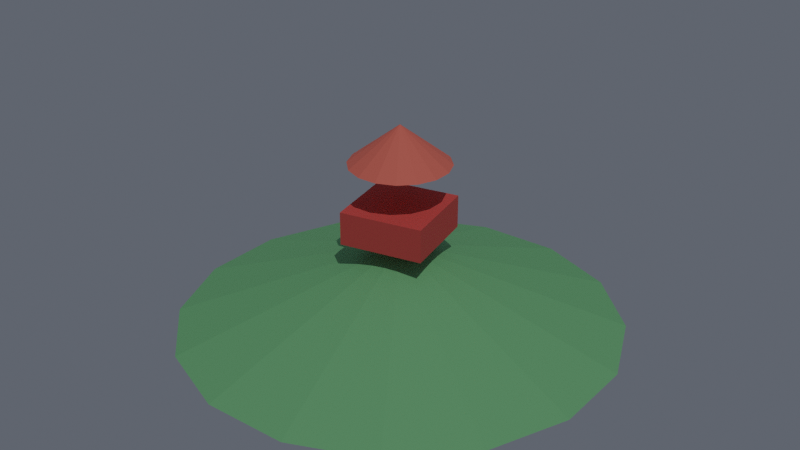

5) gemini  ('OK', 'gemini:gemini-3.8-flash')
5) openai  ('OK', 'openai:gpt-4.1-mini')


In [ ]:
#@title 6. Smoke test: validator, Blender round trip, render, then one tiny call to each LLM
DUO_KEY = secrets.token_urlsafe(16)
os.environ.update(DUO_KEY=DUO_KEY, ADDON_SRC="/content/x3d-blender-io/source", BLENDER_CMD=BLENDER_CMD, MCP_URL="http://127.0.0.1:8000/mcp",
                  OUT_DIR="/content/duo_out", DUO_MAX_RUNS=str(MAX_RUNS))
sys.path.insert(0, "/content/duo")
import importlib, coordinator as c; importlib.reload(c)

SAMPLE = """<?xml version="1.0" encoding="UTF-8"?>
<X3D profile="Immersive" version="4.0"><head><meta name="title" content="Pagoda"/></head><Scene>
<NavigationInfo type='"EXAMINE" "ANY"'/><Background skyColor="0.4 0.6 0.95"/><Viewpoint description="front" position="0 3 14" orientation="1 0 0 -0.15"/>
<DirectionalLight direction="-0.4 -1 -0.5" intensity="0.9"/>
<Shape><Appearance><Material diffuseColor="0.2 0.6 0.25"/></Appearance><Cone bottomRadius="8" height="3"/></Shape>
<Transform translation="0 2.4 0"><Shape><Appearance><Material diffuseColor="0.8 0.1 0.1"/></Appearance><Box size="3 1.2 3"/></Shape></Transform>
<Transform translation="0 5.2 0"><Shape><Appearance><Material diffuseColor="0.9 0.2 0.15"/></Appearance><Cone bottomRadius="1.8" height="1.4"/></Shape></Transform>
</Scene></X3D>"""
os.makedirs("/content/smoke", exist_ok=True); open("/content/smoke/in.x3d", "w").write(SAMPLE)

print("1) validator      ", await c.check(SAMPLE))
rt = c.worker("roundtrip", "/content/smoke/in.x3d", "/content/smoke/out.x3d"); print("2) blender round trip", {k: rt.get(k) for k in ("ok", "stats", "error")})
if rt.get("ok"):
    print("3) re-export valid ", (await c.check(open("/content/smoke/out.x3d").read()))["ok"])
rr = c.worker("render", "/content/smoke/in.x3d", "/content/smoke/out.png"); print("4) render          ", rr.get("ok"), rr.get("error"))
if rr.get("ok"):
    from IPython.display import Image, display; display(Image("/content/smoke/out.png"))
for name, fn in (("gemini", c.call_gemini), ("openai", c.call_openai)):
    if os.environ.get(name.upper() + "_API_KEY"):
        try:
            print("5) %-7s" % name, fn("Reply with the single word OK.", "Be terse."))
        except Exception as e:
            print("5) %-7s FAILED:" % name, type(e).__name__, str(e)[:300])
    else:
        print("5) %-7s skipped (no key)" % name)

preset=smoke budget=12 min workers=2 seed=1337

  INFO [env] inventory                                             1.8s  {"python": "3.13.16", "cpus": 2, "mode": "bpy-wheel", "preset": "smoke", "ram_gb": "12.7 (free 10.6)", "disk_free_gb": 203.9, "blender": "5.2.2 LTS", 
  PASS [env] blender importable / runnable                         0.0s  5.2.2 LTS
  PASS [pure] extract_xml on 7 adversarial replies                  0.0s  
  FAIL [mcp] server process alive                                  0.0s  poll=3
  PASS [mcp] /pulse                                                0.0s  {"status":"ok"}
  PASS [mcp] tools/list (35 tools)                                 0.1s  missing: [] | all: add_child, add_route, add_x3d_route, animate_x3d_node, autofix_x3d, compose_scene, convert_x3d, create_geometry, create_node, creat
  PASS [mcp] list_profiles                                         0.0s  8629 chars
  PASS [mcp] path= is refused over HTTP (file-read guard)          0.0s  {   "valid": false, 

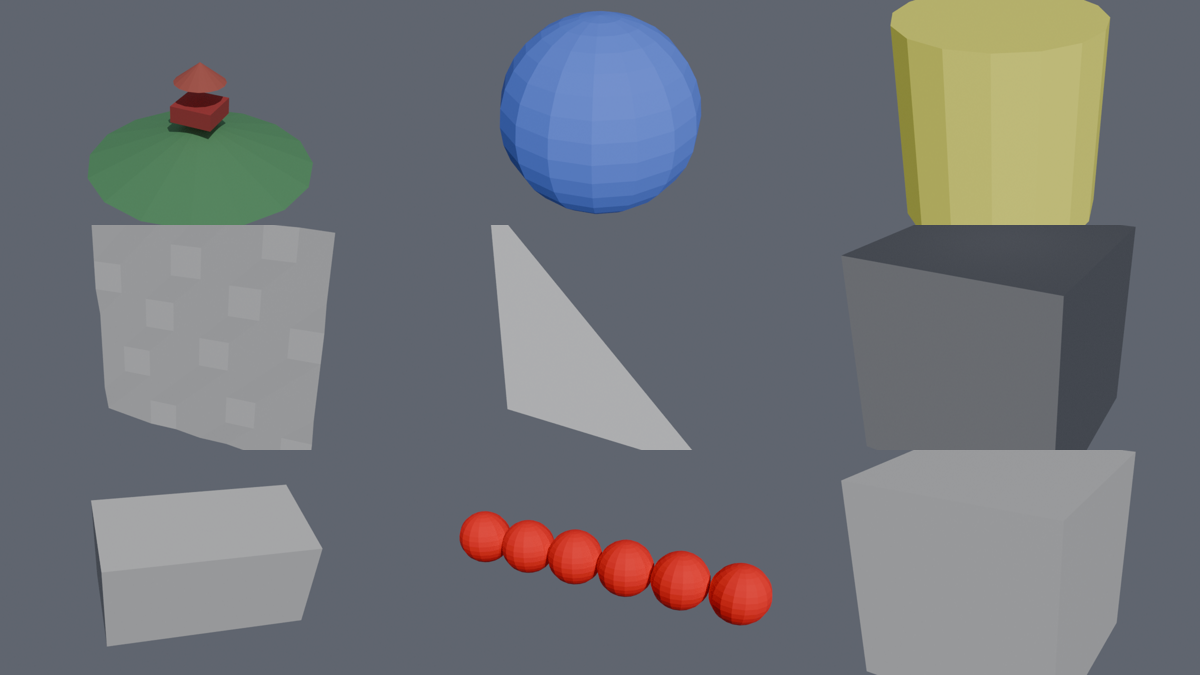

  INFO [blender] light intensity over 3 generations                    3.6s  known drift: 1.0 -> [0.571429, 0.326531, 0.186589]
  PASS [blender] 5 textured imports in one session                     1.3s  imports done=5  | patch (a) applied
  PASS [blender] 16384 colliding DEF names                             0.2s  0.06s, 16384 unique (patch d: needs < 5 s)
  PASS [app] no key -> 401                                         0.0s  401
  PASS [app] wrong key -> 401                                      0.0s  401
  PASS [app] 10 KB key -> 401                                      0.0s  401
  WARN [app] non-ASCII key -> 401, not 500                         0.0s  status 500 (secrets.compare_digest rejects non-ASCII str)
  PASS [app] ?key= works and sets cookie                           0.0s  200, httponly=True
  PASS [app] X-Duo-Key header works                                0.1s  200
  PASS [app] cookie works                                          0.1s  200
  PASS [app] /api/health report

In [ ]:
#@title 6. Smoke test: validator, MCP, Blender, render, web app, fuzz, soak, LLMs
PRESET = "smoke"          #@param ["smoke", "heavy", "50000"]
TIME_BUDGET_MIN = 12      #@param {type:"integer"}
SPEND_ON_LLMS = True     #@param {type:"boolean"}
LLM_PROMPTS = 3           #@param {type:"integer"}
SEED = 1337               #@param {type:"integer"}
# smoke ~ 2 min | heavy ~ 15 min (set budget 20+) | 50000 = 50,000 fuzz mutations + 500 Blender runs (set budget 90+)
# Every heavy tier stops gracefully when its share of the time budget is spent.

import asyncio, collections, concurrent.futures as cf, hashlib, importlib, json, random, struct, tempfile, zlib
import xml.etree.ElementTree as ET
from contextlib import asynccontextmanager

DUO_KEY = globals().get("DUO_KEY") or secrets.token_urlsafe(16)   # keep the key if the server (cell 7) is already running
os.environ.update(DUO_KEY=DUO_KEY, ADDON_SRC="/content/x3d-blender-io/source", BLENDER_CMD=globals().get("BLENDER_CMD", ""),
                  MCP_URL="http://127.0.0.1:8000/mcp", OUT_DIR="/content/duo_out", DUO_MAX_RUNS=str(MAX_RUNS))
sys.path.insert(0, "/content/duo")
import coordinator as c; importlib.reload(c)

P = {"smoke": dict(fuzz=200, diff=6, soak=6, shapes=(10, 200), tris=(2_000,), depth=100, conc=16),
     "heavy": dict(fuzz=3_000, diff=60, soak=60, shapes=(10, 200, 2_000), tris=(2_000, 50_000), depth=400, conc=32),
     "50000": dict(fuzz=50_000, diff=400, soak=500, shapes=(10, 200, 2_000, 10_000), tris=(2_000, 50_000, 500_000), depth=1000, conc=64)}[PRESET]
WORKERS = max(1, min(os.cpu_count() or 1, 8))
rnd = random.Random(SEED)
T0 = time.time(); DEADLINE = T0 + TIME_BUDGET_MIN * 60
S = "/content/smoke"; shutil.rmtree(S, ignore_errors=True); os.makedirs(S + "/failures"); os.makedirs(S + "/scenes")
left = lambda: DEADLINE - time.time()
share = lambda frac: time.time() + max(0.0, left()) * frac
PATCHED_HUGE = "huge_tree" in open("/content/x3d_mcp/src/validation/validate.py").read()
R = []

def rec(tier, name, status, detail="", secs=0.0):
    R.append(dict(tier=tier, name=name, status=status, secs=round(secs, 2), detail=str(detail)[:400]))
    print("  %-4s [%s] %-50s %6.1fs  %s" % (status, tier, name, secs, str(detail)[:150].replace("\n", " ")))

def keep(name, text):
    p = "%s/failures/%s" % (S, re.sub(r"[^\w.-]", "_", name)[:90]); open(p, "w", encoding="utf-8", errors="replace").write(text); return p

def leaf(e):
    """readable one-liner for an exception, unwrapping anyio/ExceptionGroup wrappers"""
    if getattr(e, "exceptions", None): return "; ".join(leaf(x) for x in e.exceptions)[:300]
    return "%s: %s" % (type(e).__name__, str(e).split("\n")[0][:160])

def pct(xs, p):
    xs = sorted(xs); return xs[min(len(xs) - 1, int(len(xs) * p))] if xs else 0.0

def lat(xs):
    return "n=%d p50=%.0fms p95=%.0fms max=%.0fms" % (len(xs), pct(xs, .5) * 1e3, pct(xs, .95) * 1e3, max(xs, default=0) * 1e3)

def rss_mb(proc):
    try:
        import psutil; return psutil.Process(proc.pid).memory_info().rss / 2**20
    except Exception:
        return -1.0

@asynccontextmanager
async def mcp_session():
    from mcp import ClientSession
    from mcp.client.streamable_http import streamablehttp_client
    async with streamablehttp_client(c.MCP_URL) as (r, w, _):
        async with ClientSession(r, w) as s:
            await s.initialize(); yield s

async def tool(s, name, args):
    res = await s.call_tool(name, args)
    return "\n".join(x.text for x in res.content if getattr(x, "text", None)), bool(getattr(res, "isError", False))

# ---------------------------------------------------------------- scene builders
def scene(body, version="4.0", profile="Immersive", head=""):
    return '<?xml version="1.0" encoding="UTF-8"?>\n<X3D profile="%s" version="%s"><head>%s</head><Scene>%s</Scene></X3D>' % (profile, version, head, body)

SAMPLE = """<?xml version="1.0" encoding="UTF-8"?>
<X3D profile="Immersive" version="4.0"><head><meta name="title" content="Pagoda"/></head><Scene>
<NavigationInfo type='"EXAMINE" "ANY"'/><Background skyColor="0.4 0.6 0.95"/><Viewpoint description="front" position="0 3 14" orientation="1 0 0 -0.15"/>
<DirectionalLight direction="-0.4 -1 -0.5" intensity="0.9"/>
<Shape><Appearance><Material diffuseColor="0.2 0.6 0.25"/></Appearance><Cone bottomRadius="8" height="3"/></Shape>
<Transform translation="0 2.4 0"><Shape><Appearance><Material diffuseColor="0.8 0.1 0.1"/></Appearance><Box size="3 1.2 3"/></Shape></Transform>
<Transform translation="0 5.2 0"><Shape><Appearance><Material diffuseColor="0.9 0.2 0.15"/></Appearance><Cone bottomRadius="1.8" height="1.4"/></Shape></Transform>
</Scene></X3D>"""

def shape(geom, color="0.5 0.5 0.5", extra=""):
    return '<Shape><Appearance><Material diffuseColor="%s"/></Appearance>%s%s</Shape>' % (color, geom, extra)

def grid_ifs(g):
    """g x g quads -> 2*g*g triangles, (g+1)^2 vertices"""
    pts = " ".join("%d %d %.3f" % (x, y, ((x * 7 + y * 13) % 17) * 0.01) for y in range(g + 1) for x in range(g + 1))
    idx = []
    for y in range(g):
        for x in range(g):
            a = y * (g + 1) + x; b = a + 1; d = a + g + 1; e = d + 1
            idx += [a, b, e, -1, a, e, d, -1]
    return '<IndexedFaceSet coordIndex="%s"><Coordinate point="%s"/></IndexedFaceSet>' % (" ".join(map(str, idx)), pts)

def many_shapes(n):
    parts = []
    for i in range(n):
        g = rnd.choice(["Box", "Sphere", "Cone", "Cylinder"]); t = "%d %d %d" % (i % 50, (i // 50) % 50, i // 2500)
        body = shape("<%s/>" % g, "%.2f %.2f %.2f" % (rnd.random(), rnd.random(), rnd.random()))
        parts.append('<Transform translation="%s">%s</Transform>' % (t, body))
    return scene("".join(parts))

def deep(n):
    return scene("<Transform>" * n + shape("<Box/>") + "</Transform>" * n)

def big_splat_xml(n, tail=""):
    pos = " ".join("%.6f %.6f %.6f" % (i * 0.001, (i % 97) * 0.5, -i * 0.0007) for i in range(n))
    return '<?xml version="1.0" encoding="UTF-8"?>\n<X3D profile="Immersive" version="4.1"><Scene><GaussianSplats DEF="Big" positions="%s"/>%s</Scene></X3D>' % (pos, tail)

def png1x1(path):
    ch = lambda t, d: struct.pack(">I", len(d)) + t + d + struct.pack(">I", zlib.crc32(t + d) & 0xFFFFFFFF)
    open(path, "wb").write(b"\x89PNG\r\n\x1a\n" + ch(b"IHDR", struct.pack(">IIBBBBB", 1, 1, 8, 2, 0, 0, 0)) + ch(b"IDAT", zlib.compress(b"\x00\xff\x00\x00")) + ch(b"IEND", b""))
png1x1(S + "/scenes/tex.png")

# ---------------------------------------------------------------- corpora
# expect: True = must validate, False = must NOT validate, None = just report what the validator says
CORPUS = [
    ("sample pagoda", SAMPLE, True),
    ("empty scene", scene(""), None),
    ("box", scene(shape("<Box/>")), True), ("sphere", scene(shape("<Sphere/>")), True),
    ("cone+cylinder", scene(shape("<Cone/>") + shape("<Cylinder/>")), True),
    ("indexed face set", scene(shape(grid_ifs(3))), True),
    ("DEF/USE", scene('<Shape DEF="a"><Appearance><Material/></Appearance><Box/></Shape><Transform translation="3 0 0"><Shape USE="a"/></Transform>'), True),
    ("x3d 3.3 document", scene(shape("<Box/>"), version="3.3"), None),
    ("unicode meta", scene("", head='<meta name="title" content="Pagoda \u5854 \u00e9\u00e8 \U0001F3EF"/>'), True),
    ("not xml", "hello world", False), ("empty string", "", False),
    ("unclosed tag", scene(shape("<Box/>")).replace("</Scene>", ""), False),
    ("unknown element", scene("<Banana/>"), False),
    ("bad field name", scene(shape('<Box siz="1 1 1"/>')), False),
    ("python-style boolean", scene(shape('<Box solid="True"/>')), False),
    ("short SFColor", scene('<Shape><Appearance><Material diffuseColor="1 0"/></Appearance><Box/></Shape>'), None),
    ("USE of undefined DEF", scene('<Shape USE="nope"/>'), False),
    ("duplicate DEF", scene('<Shape DEF="a"><Box/></Shape><Shape DEF="a"><Sphere/></Shape>'), None),
    ("control char", scene("").replace("<Scene>", "<Scene>\x00"), False),
    ("missing profile", SAMPLE.replace(' profile="Immersive"', ""), None),
    ("wrong root", "<html><body/></html>", False),
]
EXTRACT = [("plain", "<?xml version='1.0'?><X3D/>", "<?xml"), ("fenced", "Sure!\n```xml\n<?xml version='1.0'?><X3D></X3D>\n```\nEnjoy", "<?xml"),
           ("fenced no lang", "```\n<X3D></X3D>\n```", "<X3D"), ("prose around", "Here: <X3D profile='Core'></X3D> thanks", "<X3D"),
           ("truncated", "<?xml version='1.0'?><X3D><Scene>", "<?xml"), ("empty", "", ""), ("no xml", "I cannot do that.", "I cannot")]

# ================================================================ tier 0: inventory
def tier_inventory():
    t = time.time(); info = {"python": sys.version.split()[0], "cpus": os.cpu_count(), "mode": "blender-binary" if c.BLENDER_CMD else "bpy-wheel", "preset": PRESET}
    try:
        import psutil; vm = psutil.virtual_memory(); info["ram_gb"] = "%.1f (free %.1f)" % (vm.total / 2**30, vm.available / 2**30)
    except Exception: pass
    info["disk_free_gb"] = round(shutil.disk_usage("/content").free / 2**30, 1)
    bl = (sh(c.BLENDER_CMD + " --version", quiet=True).stdout.splitlines() or ["?"])[0] if c.BLENDER_CMD else sh("%s -c 'import bpy;print(bpy.app.version_string)'" % sys.executable, quiet=True).stdout.strip()
    info["blender"] = bl
    for d in ("x3d_mcp", "x3d-blender-io"):
        info[d] = sh("cd /content/%s && echo $(git rev-parse --short HEAD) dirty_files=$(git status --porcelain | wc -l)" % d, quiet=True).stdout.strip()
    info["keys"] = [k for k in ("GEMINI_API_KEY", "OPENAI_API_KEY") if os.environ.get(k)] or "none"
    info["huge_tree patch in validator"] = PATCHED_HUGE
    rec("env", "inventory", "INFO", json.dumps(info), time.time() - t)
    ok = "?" not in bl and bl != ""
    rec("env", "blender importable / runnable", "PASS" if ok else "FAIL", bl)

def tier_pure():
    t = time.time(); bad = []
    for name, text, must_start in EXTRACT:
        try:
            out = c.extract_xml(text)
            if not out.startswith(must_start): bad.append("%s -> %r" % (name, out[:40]))
        except Exception as e: bad.append("%s raised %s" % (name, e))
    rec("pure", "extract_xml on %d adversarial replies" % len(EXTRACT), "PASS" if not bad else "FAIL", "; ".join(bad), time.time() - t)

# ================================================================ tier 1: MCP server
async def tier_mcp():
    t = time.time(); proc = globals().get("mcp_proc")
    rec("mcp", "server process alive", "PASS" if proc is not None and proc.poll() is None else "FAIL", "poll=%s" % (proc.poll() if proc else "no mcp_proc (run cell 5)"))
    t = time.time()
    try:
        body = urllib.request.urlopen("http://127.0.0.1:8000/pulse", timeout=5).read().decode(); rec("mcp", "/pulse", "PASS" if '"ok"' in body else "WARN", body.strip(), time.time() - t)
    except Exception as e: rec("mcp", "/pulse", "FAIL", e, time.time() - t)
    t = time.time()
    try:
        async with mcp_session() as s:
            tools = (await s.list_tools()).tools; names = sorted(x.name for x in tools)
            need = {"validate_x3d", "validate_semantic", "repair_x3d", "list_profiles"}
            rec("mcp", "tools/list (%d tools)" % len(names), "PASS" if need <= set(names) else "FAIL", "missing: %s | all: %s" % (sorted(need - set(names)), ", ".join(names)), time.time() - t)
            out, err = await tool(s, "list_profiles", {}); rec("mcp", "list_profiles", "PASS" if out and not err else "FAIL", "%d chars" % len(out))
            out, err = await tool(s, "validate_x3d", {"path": "/etc/hostname"})
            leaked = open("/etc/hostname").read().strip() in out if os.path.exists("/etc/hostname") else False
            rec("mcp", "path= is refused over HTTP (file-read guard)", "PASS" if ("disabled" in out.lower() or "not found" in out.lower()) and not leaked else "FAIL", out[:120].replace("\n", " "))
    except Exception as e: rec("mcp", "session", "FAIL", "%s: %s" % (type(e).__name__, e), time.time() - t)
    try:
        import psutil; socks = sorted({"%s:%s" % (x.laddr.ip, x.laddr.port) for x in psutil.net_connections("tcp") if x.status == "LISTEN" and x.laddr.port in (8000, 8080)})
    except Exception as e: socks = ["unknown (%s)" % e]
    rec("mcp", "listening sockets (8000 = validator, 8080 = app)", "INFO", " | ".join(socks) + "   <- never tunnel :8000 directly, it has no key check")

# ================================================================ tier 2: validator corpus, repair, determinism
async def tier_validator():
    for name, xml, expect in CORPUS:
        t = time.time()
        try:
            v1 = await c.check(xml); v2 = await c.check(xml)
        except Exception as e:
            rec("validator", name, "FAIL", "raised %s: %s" % (type(e).__name__, e), time.time() - t); continue
        det = v1["ok"] == v2["ok"] and v1["xsd_errors"] == v2["xsd_errors"]
        why = (v1["xsd_errors"] + v1["semantic_errors"] or ["no complaints"])[0]
        if not det: rec("validator", name, "FAIL", "NON-DETERMINISTIC verdict", time.time() - t)
        elif expect is None: rec("validator", name, "INFO", "ok=%s | %s" % (v1["ok"], why), time.time() - t)
        elif v1["ok"] == expect: rec("validator", name, "PASS", "ok=%s | %s" % (v1["ok"], why[:90]), time.time() - t)
        else: rec("validator", name, "FAIL", "expected ok=%s got %s | %s | %s" % (expect, v1["ok"], why[:80], keep("val_" + name, xml)), time.time() - t)

async def tier_repair():
    cases = [("python booleans", scene(shape('<Box solid="True"/>'))), ("short color", scene('<Shape><Appearance><Material diffuseColor="1 0"/></Appearance><Box/></Shape>')),
             ("bad containerField", scene('<Shape><Appearance><PhysicalMaterial><ImageTexture url="tex.png"/></PhysicalMaterial></Appearance><Box/></Shape>')),
             ("missing xml decl", SAMPLE.split("\n", 1)[1]), ("USE before DEF", scene('<Shape USE="a"/><Shape DEF="a"><Box/></Shape>'))]
    for name, xml in cases:
        t = time.time()
        try:
            before = await c.check(xml); fixed, changes = await c.repair(xml); after = await c.check(fixed); again, _ = await c.repair(fixed)
            status = "PASS" if after["ok"] else "INFO"
            rec("repair", name, status, "before ok=%s -> after ok=%s, %d change(s)%s" % (before["ok"], after["ok"], len(changes), "" if again == fixed else " | NOT idempotent"), time.time() - t)
        except Exception as e: rec("repair", name, "FAIL", "%s: %s" % (type(e).__name__, e), time.time() - t)
    t = time.time(); fixed, changes = await c.repair(SAMPLE); after = await c.check(fixed)
    rec("repair", "repair never breaks a valid scene", "PASS" if after["ok"] else "FAIL", "%d change(s) on a valid doc" % len(changes), time.time() - t)

# ================================================================ tier 3: hostile input to the validator
async def raw(xml, timeout=120):
    """one validate_x3d call on its own session; a failure comes back as {"_exc": "..."} instead of poisoning the caller"""
    try:
        async with mcp_session() as s: return json.loads((await asyncio.wait_for(tool(s, "validate_x3d", {"content": xml}), timeout))[0])
    except BaseException as e:
        if isinstance(e, (KeyboardInterrupt, SystemExit)): raise
        return {"_exc": leaf(e)}

def say(v): return v["_exc"] if "_exc" in v else "valid=%s %s" % (v.get("valid"), (v.get("errors") or [""])[0][:80])

async def tier_hostile():
    sizes = [120_000, 140_000] + ([355_000] if PRESET != "smoke" else [])      # ~3.7 MB, ~4.5 MB, ~11.4 MB (one attribute)
    for n in sizes:
        xml = big_splat_xml(n); mb = len(xml.encode()) / 1e6; t = time.time(); v = await raw(xml, 300)
        if "_exc" in v and "413" in v["_exc"]: rec("hostile", "HTTP body of %.1f MB" % mb, "INFO", "413 from the MCP server: HTTP bodies over ~4 MiB are refused before validation (measured: 4.0 MB ok, 4.2 MB refused)", time.time() - t)
        elif "_exc" in v: rec("hostile", "HTTP body of %.1f MB" % mb, "FAIL", v["_exc"], time.time() - t)
        else: rec("hostile", "HTTP body of %.1f MB (one attribute)" % mb, "PASS" if v.get("valid") is not False or mb > 10 else "FAIL", say(v), time.time() - t)
    t = time.time()
    try: await c.check(big_splat_xml(140_000)); rec("hostile", "coordinator check() on a 4.5 MB scene", "PASS", "handled", time.time() - t)
    except BaseException as e:
        if isinstance(e, (KeyboardInterrupt, SystemExit)): raise
        rec("hostile", "coordinator check() on a 4.5 MB scene", "WARN", "raises (%s): a large Blender re-export would make /api/run return 500" % leaf(e)[:70], time.time() - t)
    # the huge_tree patch is transport-independent, so check it by calling the validator in-process (subprocess keeps its memory out of this kernel)
    code = ("import sys,time,json;sys.path.insert(0,'/content/x3d_mcp/src')\nfrom validation.validate import validate_xml\n"
            "def big(n,tail=''):\n pos=' '.join('%.6f %.6f %.6f'%(i*0.001,(i%97)*0.5,-i*0.0007) for i in range(n))\n return '<?xml version=\"1.0\"?><X3D profile=\"Immersive\" version=\"4.1\"><Scene><GaussianSplats DEF=\"B\" positions=\"'+pos+'\"/>'+tail+'</Scene></X3D>'\n"
            "out={}\nfor k,x in (('ok',big(355000)),('broken',big(355000,'<Broken>'))):\n t=time.time();r=validate_xml(x);out[k]=[r.get('valid'),r.get('verdict'),(r.get('errors') or [''])[0][:90],round(time.time()-t,1)]\nprint(json.dumps(out))")
    open(S + "/hugetree.py", "w").write(code); t = time.time(); r = sh("%s %s/hugetree.py" % (sys.executable, S), quiet=True)
    try:
        o = json.loads(r.stdout.strip().splitlines()[-1]); good = o["ok"][1] == "valid" and o["broken"][0] is False
        rec("hostile", "11.4 MB attribute, validator called in-process", ("PASS" if good else "FAIL") if PATCHED_HUGE else "INFO", "%s | %s" % (o, "huge_tree patch present" if PATCHED_HUGE else "patch NOT applied: a parse error here is expected"), time.time() - t)
    except Exception: rec("hostile", "11.4 MB attribute, validator called in-process", "FAIL", (r.stderr or r.stdout)[-200:], time.time() - t)
    marker = "XXE-" + secrets.token_hex(8); open(S + "/xxe.txt", "w").write(marker)
    t = time.time(); v = await raw('<?xml version="1.0"?><!DOCTYPE X3D [<!ENTITY x SYSTEM "file://%s/xxe.txt">]><X3D profile="Immersive" version="4.0"><head><meta name="t" content="&x;"/></head><Scene/></X3D>' % S)
    rec("hostile", "XXE: external entity must not be read", "FAIL" if marker in json.dumps(v) else "PASS", say(v), time.time() - t)
    ents = "".join('<!ENTITY %s "%s">' % (n2, "&%s;" % p * 10) for p, n2 in zip("abcde", "bcdef")); t = time.time()
    v = await raw('<?xml version="1.0"?><!DOCTYPE X3D [<!ENTITY a "aaaaaaaaaa">%s]><X3D profile="Immersive" version="4.0"><head><meta name="t" content="&f;"/></head><Scene/></X3D>' % ents, 60)
    el = time.time() - t; rec("hostile", "entity expansion (1 MB)", "FAIL" if "_exc" in v else ("PASS" if el < 20 else "WARN"), say(v), el)
    for depth in (50, P["depth"]):
        t = time.time(); v = await raw(deep(depth), 60); rec("hostile", "nesting depth %d" % depth, "FAIL" if "_exc" in v else "INFO", say(v), time.time() - t)
    for nm, xml in (("empty content", ""), ("only whitespace", "   \n"), ("NUL + huge line", "\x00" * 10 + "a" * 200_000)):
        v = await raw(xml); rec("hostile", nm, "FAIL" if "_exc" in v or v.get("valid") is True else "PASS", say(v))

# ================================================================ tier 4: concurrency on the validator
async def tier_concurrency():
    docs = [SAMPLE, scene("<Banana/>"), many_shapes(100)]
    async with mcp_session() as s:
        ref = [json.loads((await tool(s, "validate_x3d", {"content": d}))[0]).get("valid") for d in docs]
    lats, bad, errs = [], 0, []
    async def one(i):
        nonlocal bad
        t = time.time()
        try:
            async with mcp_session() as s:
                v = json.loads((await tool(s, "validate_x3d", {"content": docs[i % 3]}))[0]).get("valid")
            lats.append(time.time() - t); bad += v != ref[i % 3]
        except Exception as e: errs.append("%s: %s" % (type(e).__name__, str(e)[:80]))
    t = time.time(); await asyncio.gather(*(one(i) for i in range(P["conc"] * 4)))
    rec("concurrency", "%d parallel sessions" % (P["conc"] * 4), "PASS" if not bad and not errs else "FAIL", "mismatches=%d errors=%d %s | %s" % (bad, len(errs), errs[:2], lat(lats)), time.time() - t)

# ================================================================ tier 5: fuzz the validator over one persistent session
JUNK = ["<", ">", "&", "&amp;", "&bogus;", '"', "'", "\x00", "\x1b", "\u202e", "\U0001F4A5", "]]>", "<!--", "-->", "<![CDATA[", "\ufeff", "\r\n", "\t"]
VALS = ["", "0", "-1", "1e309", "-1e-400", "NaN", "inf", "1 2", "1 2 3 4 5", "True", "FALSE", "\u00e9", "&amp;", "'", "9" * 400, " ".join(["1"] * 3000), "1,2,3", "0x10", "+1", ".5", "5."]
TAGS = ["Shape", "Box", "Sphere", "Transform", "Group", "Material", "Appearance", "Viewpoint", "Coordinate", "Banana", "ROUTE", "Script", "ProtoDeclare", "IS", "NavigationInfo"]
FUZZ_BASE = [SAMPLE, many_shapes(6), scene(shape(grid_ifs(3))), scene('<Shape DEF="a"><Box/></Shape><Transform><Shape USE="a"/></Transform><PointLight intensity="2"/>')]

def mutate(s, r):
    for _ in range(r.randint(1, 3)):
        k = r.randrange(11); i = r.randrange(len(s)) if s else 0
        if k == 0: s = s[:i] + s[i + r.randint(1, 60):]
        elif k == 1: s = s[:i] + r.choice(JUNK) + s[i:]
        elif k in (2, 3, 4):
            m = list(re.finditer(r'(\w+)="([^"]*)"', s))
            if m:
                a = r.choice(m); s = s[:a.start(2)] + r.choice(VALS) + s[a.end(2):] if k != 4 else s[:a.start()] + s[a.end():]
        elif k == 5:
            m = list(re.finditer(r"<(\w+)", s))
            if m: a = r.choice(m); s = s[:a.start(1)] + r.choice(TAGS) + s[a.end(1):]
        elif k == 6:
            m = list(re.finditer(r"<Shape\b.*?</Shape>|<Transform\b.*?</Transform>", s, re.S))
            if m: a = r.choice(m); s = s[:a.end()] + a.group(0) * r.randint(1, 5) + s[a.end():]
        elif k == 7:
            m = list(re.finditer(r"-?\d+\.?\d*", s))
            if m: a = r.choice(m); s = s[:a.start()] + r.choice(["0", "-1", "1e38", "999999999999", "-0", "0.0000001"]) + s[a.end():]
        elif k == 8: s = s.replace("</Scene>", "<Transform>" * r.randint(1, 30) + "</Scene>", 1)
        elif k == 9: s = s[:i] + chr(r.choice([0x7f, 0x80, 0xd7ff, 0xe000, 0xfffd, 0x10000, 0x1f600])) + s[i + 1:]
        else: s = s[:i] + s[i:i + r.randint(1, 30)] * r.randint(2, 20) + s[i:]
    return s

async def tier_fuzz():
    stop = share(0.40); verdicts = collections.Counter(); sigs = collections.Counter(); lats = []; valid_mutants = {}; crashes = []; crash_sigs = collections.Counter(); first_repro = {}; slow = 0; n = 0
    rss0 = rss_mb(mcp_proc); t0 = time.time()
    s_cm = mcp_session(); s = await s_cm.__aenter__()
    try:
        while n < P["fuzz"] and time.time() < stop:
            xml = mutate(rnd.choice(FUZZ_BASE), rnd); n += 1; t = time.time()
            try:
                out, err = await asyncio.wait_for(tool(s, "validate_x3d", {"content": xml}), 60)
                try: v = json.loads(out)
                except ValueError: raise ValueError("tool returned non-JSON: " + out[:110].replace("\n", " "))
                d = time.time() - t; lats.append(d)
                if not isinstance(v, dict) or "valid" not in v: raise ValueError("no 'valid' key: %s" % out[:80])
                if v["valid"] is True and v.get("errors"): raise ValueError("valid=True but errors present")
                if v["valid"] is False and not v.get("errors"): sigs["INVALID WITHOUT ANY ERROR"] += 1
                verdicts[v.get("verdict") or str(v["valid"])] += 1
                for e in (v.get("errors") or [])[:1]: sigs[re.sub(r"\d+(\.\d+)?", "N", e)[:70]] += 1
                if d > 10: slow += 1
                if v["valid"] is True and len(valid_mutants) < P["diff"] * 3 and len(xml) < 200_000: valid_mutants[hashlib.md5(xml.encode("utf-8", "replace")).hexdigest()] = xml
                if n % 4 == 0:
                    out2, _ = await tool(s, "validate_semantic", {"content": xml})
                    if not out2: raise ValueError("empty semantic reply")
                if n % 8 == 0 and v["valid"] is True:
                    rp = json.loads((await tool(s, "repair_x3d", {"content": xml}))[0]); fx = rp.get("fixed") or xml
                    if (await c.check(fx))["ok"] is False and (await c.check(xml))["ok"]: raise ValueError("repair_x3d broke a valid mutant")
            except Exception as e:
                sig = re.sub(r"\b\d+\b", "N", "%s: %s" % (type(e).__name__, str(e)[:110])); crash_sigs[sig] += 1; crashes.append(sig)
                if crash_sigs[sig] == 1: first_repro[sig] = keep("fuzz_%d.x3d" % n, xml)
                if mcp_proc.poll() is not None:
                    rec("fuzz", "server died during fuzz", "FAIL", "mutant #%d | log tail: %s" % (n, open("/content/mcp.log").read()[-300:]), time.time() - t0); break
                try:
                    await s_cm.__aexit__(None, None, None)
                except BaseException: pass
                s_cm = mcp_session(); s = await s_cm.__aenter__()
    finally:
        try: await s_cm.__aexit__(None, None, None)
        except BaseException: pass
    el = time.time() - t0
    rec("fuzz", "%d mutants through validate_x3d" % n, "PASS" if not crashes else "FAIL", "%s | invariant breaks=%d slow(>10s)=%d | %.0f/s | %s" % (dict(verdicts), len(crashes), slow, n / max(el, 1e-9), lat(lats)), el)
    for sg, k in crash_sigs.most_common(6): rec("fuzz", "  invariant break x%d" % k, "FAIL", "%s | repro: %s" % (sg, first_repro[sg]))
    rec("fuzz", "top error shapes", "INFO", " || ".join("%dx %s" % (v, k) for k, v in sigs.most_common(4)))
    r1 = rss_mb(mcp_proc); grew = r1 - rss0
    rec("fuzz", "validator RSS growth", "WARN" if grew > 400 + n * 0.05 else "PASS", "%.0f MB -> %.0f MB over %d calls" % (rss0, r1, n))
    return list(valid_mutants.values())

# ================================================================ tier 6: Blender corpus, fidelity, light drift, repeated imports
def write_scene(name, xml): p = "%s/scenes/%s.x3d" % (S, name); open(p, "w", encoding="utf-8").write(xml); return p

BLENDER = [("sample pagoda", SAMPLE), ("sphere", scene(shape("<Sphere/>", "0.1 0.2 0.9"))), ("cylinder", scene(shape("<Cylinder/>", "0.9 0.9 0.1"))),
    ("indexed face set 8x8", scene(shape(grid_ifs(8)))),
    ("textured (1x1 png)", scene('<Shape><Appearance><ImageTexture url="tex.png"/></Appearance><IndexedFaceSet coordIndex="0 1 2 -1"><Coordinate point="0 0 0 1 0 0 0 1 0"/></IndexedFaceSet></Shape>')),
    ("point+spot+dir lights", scene('<PointLight location="0 2 0" intensity="1"/><SpotLight location="2 3 0" direction="0 -1 0" intensity="0.8"/><DirectionalLight intensity="0.5"/>' + shape("<Box/>"))),
    ("nested transforms", scene('<Transform rotation="0 1 0 0.7" scale="2 1 1"><Transform translation="1 2 3" rotation="1 0 0 0.3"><Group>%s</Group></Transform></Transform>' % shape("<Box/>"))),
    ("DEF/USE instancing", scene('<Shape DEF="a"><Appearance><Material diffuseColor="1 0 0"/></Appearance><Sphere/></Shape>' + "".join('<Transform translation="%d 0 0"><Shape USE="a"/></Transform>' % i for i in range(1, 6)))),
    ("many viewpoints", scene("".join('<Viewpoint description="v%d" position="%d 0 10"/>' % (i, i) for i in range(5)) + shape("<Box/>"))),
    ("empty scene", scene(""))]

def fidelity(a, b):
    def cnt(x):
        try: r = ET.fromstring(x)
        except Exception: return None
        c_ = collections.Counter(e.tag for e in r.iter()); return {k: c_.get(k, 0) for k in ("Shape", "PointLight", "SpotLight", "DirectionalLight", "Viewpoint")}
    ca, cb = cnt(a), cnt(b)
    return "unparseable" if ca is None or cb is None else ", ".join("%s %d->%d" % (k, ca[k], cb[k]) for k in ca if ca[k] != cb[k]) or "counts identical"

def render_ok(path):
    from PIL import Image, ImageStat
    im = Image.open(path).convert("L"); st = ImageStat.Stat(im)
    return im.size == (800, 450) and 3 < st.mean[0] < 252 and st.stddev[0] > 1, "size=%s mean=%.0f sd=%.1f" % (im.size, st.mean[0], st.stddev[0])

async def tier_blender():
    loop = asyncio.get_running_loop(); pool = cf.ThreadPoolExecutor(WORKERS); renders = []
    async def one(name, xml):
        p = write_scene(re.sub(r"\W+", "_", name), xml); out = p.replace(".x3d", ".rt.x3d"); t = time.time()
        rt = await loop.run_in_executor(pool, c.worker, "roundtrip", p, out)
        if not rt.get("ok"):
            rec("blender", name, "INFO" if name == "empty scene" else "FAIL", rt.get("error") or rt, time.time() - t); return
        back = await c.check(open(out, encoding="utf-8", errors="replace").read())
        st = rt.get("stats", {}); rec("blender", name, "PASS" if back["ok"] else "WARN", "re-export %s | %s | objs=%s verts=%s" % ("valid" if back["ok"] else "INVALID: " + (back["xsd_errors"] + back["semantic_errors"] or ["?"])[0][:70], fidelity(xml, open(out, encoding="utf-8", errors="replace").read()), st.get("objects"), st.get("vertices")), time.time() - t)
        if name != "empty scene":
            t = time.time(); png = p.replace(".x3d", ".png"); rr = await loop.run_in_executor(pool, c.worker, "render", p, png)
            if rr.get("ok"):
                good, d = render_ok(png); rec("render", name, "PASS" if good else "WARN", ("" if good else "BLANK/ODD IMAGE ") + d, time.time() - t); renders.append((name, png))
            else: rec("render", name, "FAIL", rr.get("error"), time.time() - t)
    await asyncio.gather(*(one(n, x) for n, x in BLENDER))
    if renders:
        from PIL import Image
        ims = [Image.open(p).convert("RGB").resize((400, 225)) for _, p in renders[:9]]; cols = 3; rows = (len(ims) + cols - 1) // cols
        sheet = Image.new("RGB", (400 * cols, 225 * rows)); [sheet.paste(im, (400 * (i % cols), 225 * (i // cols))) for i, im in enumerate(ims)]
        from IPython.display import display; display(sheet)

    # known defect (c): light intensity decays on every X3D -> Blender -> X3D generation. Reported, not asserted.
    cur = write_scene("light_gen0", scene('<PointLight location="0 2 0" intensity="1"/>' + shape("<Box/>"))); vals = []; t = time.time()
    for g in range(1, 4):
        out = "%s/scenes/light_gen%d.x3d" % (S, g); rt = await loop.run_in_executor(pool, c.worker, "roundtrip", cur, out)
        if not rt.get("ok"): vals.append("fail"); break
        m = re.search(r"<PointLight[^>]*intensity='?\"?([0-9.eE+-]+)", open(out).read()); vals.append(float(m.group(1)) if m else None); cur = out
    stable = all(isinstance(v, float) and abs(v - 1.0) < 1e-3 for v in vals)
    rec("blender", "light intensity over 3 generations", "PASS" if stable else "INFO", ("STABLE: the known drift (x0.571/gen) looks fixed" if stable else "known drift: 1.0 -> %s" % vals), time.time() - t)

    # patch (a): importing a textured scene twice in ONE Blender session
    script = S + "/multi_import.py"; open(script, "w").write('''import bpy, importlib, json, os, shutil, sys, tempfile, traceback
argv = sys.argv[sys.argv.index("--") + 1:] if "--" in sys.argv else sys.argv[1:]
addon, src, n = os.path.abspath(argv[0]), os.path.abspath(argv[1]), int(argv[2]); res = {"ok": False, "done": 0}
try:
    pkg = tempfile.mkdtemp(); os.symlink(addon, os.path.join(pkg, "io_scene_x3d"), target_is_directory=True); sys.path.insert(0, pkg)
    mod = importlib.import_module("io_scene_x3d")
    for i in range(n):
        try: mod.register()
        except Exception: pass
        bpy.ops.wm.read_factory_settings(use_empty=True)
        try: mod.register()
        except Exception: pass
        assert "FINISHED" in bpy.ops.import_scene.x3d(filepath=src); res["done"] = i + 1
    res["ok"] = True
except Exception as e: res["error"] = "%s: %s" % (type(e).__name__, e); res["trace"] = traceback.format_exc()[-600:]
print("RESULT_JSON" + json.dumps(res))
''')
    tex = write_scene("textured_multi", BLENDER[4][1]); cmd = ([c.BLENDER_CMD, "-b", "--factory-startup", "--python", script, "--"] if c.BLENDER_CMD else [sys.executable, script]) + [c.ADDON_SRC, tex, "5"]
    t = time.time(); p = await loop.run_in_executor(None, lambda: subprocess.run(cmd, capture_output=True, text=True, timeout=300))
    line = next((l for l in reversed(p.stdout.splitlines()) if l.startswith("RESULT_JSON")), None); res = json.loads(line[11:]) if line else {"ok": False, "error": "no result " + p.stderr[-200:]}
    patched = "texture_cache" in open("/content/x3d-blender-io/source/import_x3d.py").read() and "global material_cache, texture_cache" in open("/content/x3d-blender-io/source/import_x3d.py").read()
    rec("blender", "5 textured imports in one session", "PASS" if res["ok"] else ("FAIL" if patched else "INFO"), "imports done=%s %s | patch (a) %s" % (res.get("done"), res.get("error", ""), "applied" if patched else "NOT applied"), time.time() - t)

    # patch (d): DEF-name allocation must not be quadratic
    code = ("import sys,time;sys.path.insert(0,%r)\nfrom emit_x3d40 import _DefNames\nk=['a'+''.join('-' if (i>>b)&1 else '_' for b in range(14)) for i in range(16384)]\n"
            "d=_DefNames();t=time.perf_counter();n=[d.get('geometry',x,'ME_') for x in k];print(round(time.perf_counter()-t,2),len(set(n)))") % c.ADDON_SRC
    open(S + "/defnames.py", "w").write(code); t = time.time(); r = sh("%s %s/defnames.py" % (sys.executable, S), quiet=True)
    try:
        el, uniq = r.stdout.split(); good = float(el) < 5 and int(uniq) == 16384; rec("blender", "16384 colliding DEF names", "PASS" if good else "WARN", "%ss, %s unique (patch d: needs < 5 s)" % (el, uniq), time.time() - t)
    except Exception: rec("blender", "16384 colliding DEF names", "SKIP", (r.stderr or r.stdout)[-160:], time.time() - t)

    # differential: hostile-but-valid scenes. Anything the validator accepts, Blender should import without crashing.
    return pool

# ================================================================ tier 7: scale limits (reported, not asserted)
async def tier_scale(pool):
    loop = asyncio.get_running_loop(); stop = share(0.5)
    cases = [("%d shapes" % n, many_shapes(n)) for n in P["shapes"]] + [("grid mesh %d tris" % (2 * g * g), scene(shape(grid_ifs(g)))) for g in [int((t / 2) ** 0.5) for t in P["tris"]]]
    for name, xml in cases:
        if time.time() > stop or left() < 60: rec("scale", name, "SKIP", "time budget"); continue
        p = write_scene("scale_" + re.sub(r"\W+", "_", name), xml); t = time.time(); vt = time.time()
        if len(xml.encode()) > 4_000_000: v = {"ok": "skipped (over the ~4 MiB HTTP limit)"}
        else:
            try: v = await asyncio.wait_for(c.check(xml), 600)
            except BaseException as e:
                if isinstance(e, (KeyboardInterrupt, SystemExit)): raise
                rec("scale", name, "WARN", "validator: " + leaf(e), time.time() - t); continue
        vt = time.time() - vt; out = p.replace(".x3d", ".rt.x3d"); bt = time.time()
        rt = await loop.run_in_executor(pool, c.worker, "roundtrip", p, out, min(900, max(60, left())))
        rec("scale", name, "PASS" if rt.get("ok") else "WARN", "%.1f MB | validator %.1fs ok=%s | blender %.1fs %s | verts=%s | %s" % (len(xml) / 1e6, vt, v["ok"], time.time() - bt, "ok" if rt.get("ok") else rt.get("error", "")[:60], (rt.get("stats") or {}).get("vertices"), "rss %.0f MB" % rss_mb(mcp_proc)), time.time() - t)

# ================================================================ tier 8: differential, validator-valid mutants -> Blender
async def tier_differential(pool, mutants):
    loop = asyncio.get_running_loop(); stop = share(0.6); todo = mutants[:P["diff"]]; sem = asyncio.Semaphore(WORKERS); out = collections.Counter(); sigs = collections.Counter(); t0 = time.time(); ran = 0
    async def one(i, xml):
        nonlocal ran
        async with sem:
            if time.time() > stop: return
            ran += 1; p = write_scene("mut_%d" % i, xml); o = p + ".out"; rt = await loop.run_in_executor(pool, c.worker, "roundtrip", p, o, 120)
            if rt.get("ok"):
                back = await c.check(open(o, encoding="utf-8", errors="replace").read()); out["ok" if back["ok"] else "re-export invalid"] += 1
                if not back["ok"]: sigs["re-export: " + (back["xsd_errors"] + back["semantic_errors"] or ["?"])[0][:60]] += 1; keep("diff_reexport_%d.x3d" % i, xml)
            else:
                e = rt.get("error", "?"); kind = "hard (timeout/no result)" if ("timeout" in e or "no result" in e) else "import/export error"; out[kind] += 1; sigs[kind + ": " + e[:70]] += 1; keep("diff_%d.x3d" % i, xml)
    if not todo: rec("differential", "valid mutants -> Blender", "SKIP", "fuzz produced no valid mutants"); return
    await asyncio.gather(*(one(i, x) for i, x in enumerate(todo)))
    hard = out["hard (timeout/no result)"]
    rec("differential", "%d validator-valid mutants -> Blender" % ran, "FAIL" if hard else ("WARN" if len(out) > 1 or "ok" not in out else "PASS"), "%s" % dict(out), time.time() - t0)
    for k, v in sigs.most_common(5): rec("differential", "  signature", "INFO", "%dx %s" % (v, k))

# ================================================================ tier 9: soak
async def tier_soak(pool):
    loop = asyncio.get_running_loop(); stop = share(0.7); lats = []; fails = []; tmpglob = os.path.join(tempfile.gettempdir(), "x3dpkg_*"); tmp0 = len(glob.glob(tmpglob)); rss0 = rss_mb(mcp_proc); t0 = time.time()
    p = write_scene("soak", SAMPLE); sem = asyncio.Semaphore(WORKERS); n = 0
    async def one(i):
        nonlocal n
        async with sem:
            if time.time() > stop: return
            n += 1; t = time.time(); rt = await loop.run_in_executor(pool, c.worker, "roundtrip", p, "%s/scenes/soak_%d.x3d" % (S, i % WORKERS)); lats.append(time.time() - t)
            if not rt.get("ok"): fails.append(rt.get("error", "?")[:80])
            if i % 5 == 0:
                try: await c.check(SAMPLE)
                except Exception as e: fails.append("validator during soak: %s" % e)
    await asyncio.gather(*(one(i) for i in range(P["soak"])))
    el = time.time() - t0; rec("soak", "%d Blender round trips, %d at a time" % (n, WORKERS), "PASS" if not fails else "FAIL", "failures=%d %s | %.1f runs/min | %s" % (len(fails), fails[:2], n / max(el, 1) * 60, lat(lats)), el)
    leaked = len(glob.glob(tmpglob)) - tmp0; rec("soak", "temp dirs leaked by blender_worker", "WARN" if leaked >= n else "PASS", "%d new %s dirs in %s for %d runs" % (leaked, os.path.basename(tmpglob), tempfile.gettempdir(), n))
    rec("soak", "validator RSS", "INFO", "%.0f MB -> %.0f MB; disk free %.1f GB" % (rss0, rss_mb(mcp_proc), shutil.disk_usage("/content").free / 2**30))

# ================================================================ tier 10: the web app, in-process (no ports needed)
async def tier_app():
    import httpx
    k = DUO_KEY; saved = (c.runs_done, os.environ.get("GEMINI_API_KEY")); out_dir = c.OUT / "smoketest"; out_dir.mkdir(exist_ok=True); (out_dir / "scene.x3d").write_text("<ok/>")
    async with httpx.AsyncClient(transport=httpx.ASGITransport(app=c.app, raise_app_exceptions=False), base_url="http://t", timeout=60) as h:
        async def chk(name, coro, pred, sev="FAIL"):
            t = time.time()
            try:
                r = await coro; ok, d = pred(r); rec("app", name, "PASS" if ok else sev, d, time.time() - t); return r
            except Exception as e: rec("app", name, sev, "%s: %s" % (type(e).__name__, e), time.time() - t)
        await chk("no key -> 401", h.get("/"), lambda r: (r.status_code == 401, r.status_code))
        await chk("wrong key -> 401", h.get("/?key=nope"), lambda r: (r.status_code == 401, r.status_code))
        await chk("10 KB key -> 401", h.get("/?key=" + "a" * 10_000), lambda r: (r.status_code == 401, r.status_code))
        await chk("non-ASCII key -> 401, not 500", h.get("/?key=%C3%A9"), lambda r: (r.status_code == 401, "status %s (secrets.compare_digest rejects non-ASCII str)" % r.status_code), "WARN")
        r = await chk("?key= works and sets cookie", h.get("/?key=" + k), lambda r: (r.status_code == 200 and "duo=" in r.headers.get("set-cookie", ""), "%s, httponly=%s" % (r.status_code, "httponly" in r.headers.get("set-cookie", "").lower())))
        await chk("X-Duo-Key header works", h.get("/api/health", headers={"x-duo-key": k}), lambda r: (r.status_code == 200, r.status_code))
        await chk("cookie works", h.get("/api/health", headers={"cookie": "duo=" + k}), lambda r: (r.status_code == 200, r.status_code))
        hr = await chk("/api/health reports mcp up", h.get("/api/health?key=" + k), lambda r: (r.json().get("mcp") == "up", r.text[:140]))
        post = lambda body, **kw: h.post("/api/run?key=" + k, **({"json": body} if not kw else kw))
        await chk("empty prompt -> 400", post({"prompt": ""}), lambda r: (r.status_code == 400, r.status_code))
        await chk("invalid JSON body -> 4xx", post(None, content=b"{nope", headers={"content-type": "application/json"}), lambda r: (r.status_code < 500, r.status_code), "WARN")
        await chk("JSON list body -> 4xx", post([1, 2]), lambda r: (r.status_code < 500, r.status_code), "WARN")
        await chk("rounds='x' -> 4xx", post({"prompt": "a cube", "rounds": "x", "writer": "none", "reviewer": "none"}), lambda r: (r.status_code < 500, r.status_code), "WARN")
        await chk("writer='none' -> 4xx", post({"prompt": "a cube", "writer": "none", "reviewer": "none"}), lambda r: (r.status_code < 500, r.status_code), "WARN")
        await chk("unknown writer -> 400", post({"prompt": "a cube", "writer": "zzz"}), lambda r: (r.status_code == 400, r.status_code))
        os.environ.setdefault("GEMINI_API_KEY", "smoke-test-not-real")          # only to get past the key check; the guards below return before any LLM call
        c.runs_done = c.MAX_RUNS; await chk("run cap -> 429 (spend guard)", post({"prompt": "a cube", "reviewer": "none"}), lambda r: (r.status_code == 429, "%s %s" % (r.status_code, r.text[:70])))
        c.runs_done = 0
        async with c.lock: await chk("busy lock -> 429", post({"prompt": "a cube", "reviewer": "none"}), lambda r: (r.status_code == 429, "%s %s" % (r.status_code, r.text[:70])))
        await chk("/out serves a run file", h.get("/out/smoketest/scene.x3d?key=" + k), lambda r: (r.status_code == 200 and r.text == "<ok/>", "%s %s" % (r.status_code, r.headers.get("content-type"))))
        for nm, path in (("dot-dot", "/out/smoketest/..%2f..%2f..%2fetc%2fpasswd"), ("dot-dot rid", "/out/%2e%2e/%2e%2e/etc/passwd"), ("abs path", "/out/smoketest/%2fetc%2fpasswd")):
            await chk("/out traversal: " + nm, h.get(path + "?key=" + k), lambda r: ("root:" not in r.text and r.status_code != 200, r.status_code))
        await chk("/out NUL byte in name -> 4xx, not 500", h.get("/out/smoketest/scene.x3d%00.png?key=" + k), lambda r: (r.status_code < 500, "%s (Path.resolve raises ValueError on NUL)" % r.status_code), "WARN")
    shutil.rmtree(out_dir, ignore_errors=True); c.runs_done = saved[0]
    if saved[1] is None: os.environ.pop("GEMINI_API_KEY", None)

# ================================================================ tier 11: LLMs
async def tier_llm():
    have = [n for n in ("gemini", "openai") if os.environ.get(n.upper() + "_API_KEY") and not os.environ[n.upper() + "_API_KEY"].startswith("smoke-test")]
    for name in ("gemini", "openai"):
        if name not in have: rec("llm", "%s ping" % name, "SKIP", "no key"); continue
        t = time.time()
        try: txt, who = await asyncio.get_running_loop().run_in_executor(None, getattr(c, "call_" + name), "Reply with the single word OK.", "Be terse."); rec("llm", "%s ping" % name, "PASS" if "ok" in txt.lower() else "WARN", "%s -> %r" % (who, txt.strip()[:30]), time.time() - t)
        except Exception as e: rec("llm", "%s ping" % name, "FAIL", "%s: %s" % (type(e).__name__, str(e)[:150]), time.time() - t)
    if not SPEND_ON_LLMS: rec("llm", "end-to-end generations", "SKIP", "tick SPEND_ON_LLMS to run %d prompt(s) per provider" % LLM_PROMPTS); return
    prompts = ["a red cube on a blue floor with one point light", "a solar system with a sun and three planets on circular orbits", "a low-poly tree: brown cylinder trunk and three green cones",
               "a table with four legs and a sphere on top", "a staircase of five boxes with a spot light"][:LLM_PROMPTS]; cap = LLM_PROMPTS * len(have) * 3; used = 0
    for w in have:
        rv = next((x for x in have if x != w), "none")
        for pr in prompts:
            if used >= cap: break
            t = time.time(); used += 3
            try:
                r = await c.pipeline(pr, w, rv, 1); first = next((e for e in r["log"] if e["kind"] == "check"), {})
                rec("llm", "%s: %s" % (w, pr[:36]), "PASS" if r["valid"] else "WARN", "first-pass valid=%s rounds=%d final valid=%s round-trip ok=%s rendered=%s" % (first.get("ok"), r["rounds"], r["valid"], (r.get("roundtrip") or {}).get("ok"), r.get("rendered")), time.time() - t)
            except Exception as e: rec("llm", "%s: %s" % (w, pr[:36]), "FAIL", "%s: %s" % (type(e).__name__, str(e)[:120]), time.time() - t)

# ================================================================ run everything
print("preset=%s budget=%d min workers=%d seed=%d\n" % (PRESET, TIME_BUDGET_MIN, WORKERS, SEED))
async def main():
    tier_inventory(); tier_pure()
    for fn in (tier_mcp, tier_validator, tier_repair, tier_hostile, tier_concurrency):
        try: await fn()
        except Exception as e: rec(fn.__name__, "tier crashed", "FAIL", leaf(e))
    mutants = []
    try: mutants = await tier_fuzz()
    except Exception as e: rec("fuzz", "tier crashed", "FAIL", leaf(e))
    pool = None
    try: pool = await tier_blender()
    except Exception as e: rec("blender", "tier crashed", "FAIL", leaf(e)); pool = cf.ThreadPoolExecutor(WORKERS)
    for fn, args in ((tier_app, ()), (tier_llm, ()), (tier_differential, (pool, mutants)), (tier_scale, (pool,)), (tier_soak, (pool,))):
        try: await fn(*args)
        except Exception as e: rec(fn.__name__, "tier crashed", "FAIL", leaf(e))
await main()

# ================================================================ report
import pandas as pd
df = pd.DataFrame(R); counts = df.status.value_counts().to_dict()
json.dump(dict(preset=PRESET, seed=SEED, seconds=round(time.time() - T0), counts=counts, results=R), open(S + "/report.json", "w"), indent=1)
print("\n" + "=" * 78 + "\n%d checks in %.0fs: %s" % (len(R), time.time() - T0, counts))
for _, r in df[df.status.isin(["FAIL", "WARN"])].iterrows(): print("  %-4s [%s] %s -- %s" % (r.status, r.tier, r["name"], r.detail[:170]))
SMOKE_OK = not counts.get("FAIL")
print("\nVERDICT:", "GREEN - safe to start the server (cell 7)" if SMOKE_OK else "RED - %d failure(s); repro files in %s/failures, full report %s/report.json" % (counts["FAIL"], S, S))

In [ ]:
%%writefile /content/duo/blender_stress.py
"""Blender stress worker: imports procedural X3D scenes with the x3d-blender-io add-on and renders them with Cycles (GPU if it can).

    python blender_stress.py CONFIG.json
    blender -b --factory-startup --python blender_stress.py -- CONFIG.json

Every line that starts with EVT is a JSON event for the notebook dashboard. Anything else is Blender's own log.
Stages: import scaling | sample ladder | geometry multiplier | resolution ramp | turntable | GPU vs CPU
"""
import importlib, json, math, os, random, shutil, sys, tempfile, time, traceback

argv = sys.argv[sys.argv.index("--") + 1:] if "--" in sys.argv else sys.argv[1:]
cfg = json.load(open(argv[0]))
OUT = cfg["outdir"]
os.makedirs(OUT + "/frames", exist_ok=True); os.makedirs(OUT + "/scenes", exist_ok=True)


def emit(ev, **kw):
    print("EVT" + json.dumps(dict(ev=ev, t=time.time(), **kw)), flush=True)


try:
    import bpy
    from mathutils import Vector
except Exception as exc:
    emit("fatal", error="cannot import bpy: %s" % exc)
    sys.exit(0)

# ---------------------------------------------------------------- the add-on (same loading trick as blender_worker.py)
PKG = tempfile.mkdtemp(prefix="x3dstress_")
try:
    os.symlink(os.path.abspath(cfg["addon_src"]), os.path.join(PKG, "io_scene_x3d"), target_is_directory=True)
except OSError:
    shutil.copytree(cfg["addon_src"], os.path.join(PKG, "io_scene_x3d"))
sys.path.insert(0, PKG)
x3d_mod = importlib.import_module("io_scene_x3d")


def fresh():
    bpy.ops.wm.read_factory_settings(use_empty=True)
    try:
        x3d_mod.register()
    except Exception:
        pass
    return bpy.context.scene


# ---------------------------------------------------------------- scenes
PALETTE = ["0.90 0.20 0.20", "0.95 0.55 0.10", "0.95 0.85 0.15", "0.35 0.80 0.30", "0.15 0.65 0.60", "0.20 0.45 0.90",
           "0.50 0.30 0.85", "0.90 0.35 0.70", "0.85 0.85 0.88", "0.25 0.25 0.30"]
GEOMS = ["<Sphere radius='0.6'/>", "<Box size='1 1 1'/>", "<Cone bottomRadius='0.6' height='1.2'/>", "<Cylinder radius='0.5' height='1.2'/>"]


def showpiece(n, seed=7):
    """n shapes on a grid over a ground slab: valid X3D 4.0"""
    rnd = random.Random(seed)
    side = max(1, int(math.ceil(math.sqrt(n)))); sp = 1.6; size = side * sp + 4
    parts = ["<NavigationInfo type='\"EXAMINE\" \"ANY\"'/>", '<Viewpoint description="front" position="0 6 %d"/>' % int(size),
             '<Transform translation="0 -0.7 0"><Shape><Appearance><Material diffuseColor="0.55 0.55 0.58"/></Appearance><Box size="%.1f 0.2 %.1f"/></Shape></Transform>' % (size, size)]
    for i in range(n):
        gx, gz = divmod(i, side)
        parts.append('<Transform translation="%.2f 0 %.2f" rotation="0 1 0 %.2f"><Shape><Appearance><Material diffuseColor="%s"/></Appearance>%s</Shape></Transform>'
                     % ((gx - side / 2) * sp, (gz - side / 2) * sp, rnd.random() * 6.28, rnd.choice(PALETTE), rnd.choice(GEOMS)))
    return ('<?xml version="1.0" encoding="UTF-8"?>\n<X3D profile="Immersive" version="4.0"><head><meta name="title" content="stress %d"/></head><Scene>\n%s\n</Scene></X3D>'
            % (n, "\n".join(parts)))


def scene_file(n):
    p = "%s/scenes/showpiece_%d.x3d" % (OUT, n)
    if not os.path.exists(p):
        open(p, "w", encoding="utf-8").write(showpiece(n))
    return p


# ---------------------------------------------------------------- device, materials, world, camera
BACKEND = "CPU"


def apply_backend(scn, backend):
    """Point Cycles at a GPU backend (or CPU). Preferences are wiped by read_factory_settings, so this runs after every fresh()."""
    try:
        bpy.ops.preferences.addon_enable(module="cycles")
    except Exception:
        pass
    scn.render.engine = "CYCLES"
    if backend == "CPU":
        scn.cycles.device = "CPU"
        return ["CPU"]
    cyc = bpy.context.preferences.addons["cycles"].preferences
    cyc.compute_device_type = backend                      # TypeError when this Blender build has no such backend
    for fn in ("refresh_devices", "get_devices"):
        f = getattr(cyc, fn, None)
        if f:
            try:
                f(); break
            except Exception:
                pass
    names = []
    for d in cyc.devices:
        d.use = d.type != "CPU"
        if d.use:
            names.append(d.name)
    if not names:
        raise RuntimeError("no %s device found" % backend)
    scn.cycles.device = "GPU"
    return names


def fancy_materials():
    """Make Cycles work for its living: metal, glass, clearcoat and emissive variants of the imported materials."""
    for k, mat in enumerate(list(bpy.data.materials)):
        try:
            if not mat.use_nodes:
                mat.use_nodes = True
        except Exception:
            pass
        nt = mat.node_tree
        if nt is None:
            continue
        bsdf = next((n for n in nt.nodes if n.type == "BSDF_PRINCIPLED"), None)
        if bsdf is None:
            nt.nodes.clear()
            bsdf = nt.nodes.new("ShaderNodeBsdfPrincipled"); out = nt.nodes.new("ShaderNodeOutputMaterial")
            nt.links.new(bsdf.outputs[0], out.inputs[0])
            bsdf.inputs["Base Color"].default_value = tuple(mat.diffuse_color)

        def setv(names, v):
            for nm in names:
                s = bsdf.inputs.get(nm)
                if s is not None:
                    s.default_value = v
                    return

        kind = k % 5
        if kind == 0:
            setv(["Metallic"], 1.0); setv(["Roughness"], 0.12)
        elif kind == 1:
            setv(["Transmission Weight", "Transmission"], 1.0); setv(["Roughness"], 0.03); setv(["IOR"], 1.45)
        elif kind == 2:
            setv(["Roughness"], 0.8)
        elif kind == 3:
            setv(["Coat Weight", "Clearcoat"], 1.0); setv(["Roughness"], 0.25)
        else:
            col = bsdf.inputs["Base Color"].default_value
            for nm in ("Emission Color", "Emission"):
                s = bsdf.inputs.get(nm)
                if s is not None:
                    s.default_value = (col[0], col[1], col[2], 1.0); break
            setv(["Emission Strength"], 2.5)


def make_world(scn):
    w = bpy.data.worlds.new("stress_sky"); scn.world = w
    try:
        w.use_nodes = True
    except Exception:
        pass
    nt = w.node_tree; bg = nt.nodes.get("Background") or nt.nodes.new("ShaderNodeBackground")
    try:
        sky = nt.nodes.new("ShaderNodeTexSky")
        sky.sun_elevation = math.radians(28); sky.sun_rotation = math.radians(130)
        nt.links.new(sky.outputs["Color"], bg.inputs["Color"]); bg.inputs["Strength"].default_value = 1.0
        return "sky"
    except Exception:
        bg.inputs[0].default_value = (0.45, 0.55, 0.75, 1.0)
        sun = bpy.data.objects.new("stress_sun", bpy.data.lights.new("stress_sun", "SUN"))
        sun.data.energy = 4.0; sun.rotation_euler = (0.8, 0.2, 0.6); scn.collection.objects.link(sun)
        return "sun"


def add_camera(scn):
    cam = bpy.data.objects.new("stress_cam", bpy.data.cameras.new("stress_cam"))
    scn.collection.objects.link(cam); scn.camera = cam; cam.data.lens = 35
    meshes = [o for o in scn.objects if o.type == "MESH"]
    if not meshes:
        return cam, Vector((0, 0, 0)), 5.0
    dims = sorted(o.dimensions.length for o in meshes); med = dims[len(dims) // 2] or 1.0
    core = [o for o in meshes if o.dimensions.length <= 4 * med] or meshes        # leave the big ground slab out of the framing
    pts = [o.matrix_world @ Vector(c) for o in core for c in o.bound_box]
    lo = Vector((min(p.x for p in pts), min(p.y for p in pts), min(p.z for p in pts)))
    hi = Vector((max(p.x for p in pts), max(p.y for p in pts), max(p.z for p in pts)))
    return cam, (lo + hi) / 2, max((hi - lo).length / 2, 1.0)


def orbit(cam, centre, radius, angle, elev=0.5, k=2.2):
    ce = math.cos(elev)
    cam.location = centre + Vector((math.cos(angle) * ce, math.sin(angle) * ce, math.sin(elev))) * radius * k
    cam.rotation_euler = (centre - cam.location).to_track_quat("-Z", "Y").to_euler()


def build(path, backend=None):
    scn = fresh(); apply_backend(scn, backend or BACKEND)
    t = time.perf_counter(); r = bpy.ops.import_scene.x3d(filepath=path); secs = time.perf_counter() - t
    if "FINISHED" not in r:
        raise RuntimeError("import returned %s" % (r,))
    fancy_materials(); make_world(scn)
    cam, centre, radius = add_camera(scn)
    return scn, cam, centre, radius, secs


def scene_stats():
    bpy.context.view_layer.update()
    dg = bpy.context.evaluated_depsgraph_get(); objs = faces = 0
    for o in bpy.context.scene.objects:
        if o.type == "MESH":
            objs += 1
            try:
                faces += len(o.evaluated_get(dg).data.polygons)
            except Exception:
                faces += len(o.data.polygons)
    return objs, faces


# ---------------------------------------------------------------- rendering
def configure(scn, w, h, spp, denoise=False, persistent=True):
    r = scn.render; c = scn.cycles
    scn.render.engine = "CYCLES"
    r.resolution_x, r.resolution_y, r.resolution_percentage = int(w), int(h), 100
    r.image_settings.file_format = "PNG"; r.image_settings.color_mode = "RGB"; r.use_persistent_data = persistent
    c.samples = int(spp); c.use_adaptive_sampling = False; c.use_animated_seed = False
    c.max_bounces = 8; c.glossy_bounces = 4; c.transmission_bounces = 8; c.use_denoising = bool(denoise)
    if denoise:
        for kind in (("OPTIX",) if BACKEND == "OPTIX" else ()) + ("OPENIMAGEDENOISE",):
            try:
                c.denoiser = kind; break
            except Exception:
                pass


def render_frame(scn, stage, label, i, n, **extra):
    path = "%s/frames/%s_%03d.png" % (OUT, stage, i)
    scn.render.filepath = path
    w, h, spp = scn.render.resolution_x, scn.render.resolution_y, scn.cycles.samples
    emit("begin", stage=stage, label=label, i=i, n=n, w=w, h=h, spp=spp)
    t0 = time.perf_counter(); res = bpy.ops.render.render(write_still=True); dt = time.perf_counter() - t0
    ok = "FINISHED" in res and os.path.exists(path)
    on_gpu = scn.cycles.device == "GPU"
    emit("frame", stage=stage, label=label, i=i, n=n, secs=dt, w=w, h=h, spp=spp, msps=(w * h * spp / dt / 1e6 if dt > 0 else 0.0),
         png=path if ok else None, ok=ok, backend=BACKEND if on_gpu else "CPU", denoise=bool(scn.cycles.use_denoising), **extra)
    return ok


def probe_backend(pref):
    """First GPU backend that renders a 1-sample frame wins (this is also the kernel warm-up); otherwise CPU."""
    order = ["CPU"] if pref == "CPU" else ([pref] if pref != "auto" else ["OPTIX", "CUDA", "HIP", "ONEAPI", "METAL"])
    for b in order:
        if b == "CPU":
            break
        try:
            scn = fresh(); names = apply_backend(scn, b); add_camera(scn); make_world(scn)
            configure(scn, 64, 36, 1, False, persistent=False)
            scn.render.filepath = OUT + "/frames/_warmup.png"; t = time.perf_counter()
            emit("warmup", backend=b, devices=names)
            if "FINISHED" in bpy.ops.render.render(write_still=True) and os.path.exists(scn.render.filepath):
                emit("device", backend=b, devices=names, warmup_secs=time.perf_counter() - t); return b
            emit("warn", msg="%s warm-up render did not finish" % b)
        except Exception as exc:
            emit("warn", msg="%s unavailable: %s" % (b, str(exc)[:160]))
    emit("device", backend="CPU", devices=["CPU"], warmup_secs=0.0)
    return "CPU"


# ---------------------------------------------------------------- stages
def st_import():
    ns = cfg["import_ns"]
    for i, n in enumerate(ns):
        p = scene_file(n); scn, cam, centre, radius, secs = build(p); objs, faces = scene_stats()
        emit("import", n=n, secs=secs, objects=objs, faces=faces, bytes=os.path.getsize(p), path=p)
        configure(scn, 480, 270, 16, False); orbit(cam, centre, radius, 0.6)
        render_frame(scn, "import", "%d shapes: imported in %.2fs, %d faces" % (n, secs, faces), i, len(ns), faces=faces)


def st_ladder():
    scn, cam, centre, radius, secs = build(scene_file(cfg["hero_n"])); orbit(cam, centre, radius, 0.7)
    w, h = cfg["hero_res"]; lad = cfg["ladder"]; steps = [(s, False) for s in lad] + [(lad[-1], True)]
    for i, (spp, dn) in enumerate(steps):
        configure(scn, w, h, spp, dn and cfg["denoise"])
        render_frame(scn, "ladder", "%d samples%s" % (spp, " + denoise" if dn and cfg["denoise"] else ""), i, len(steps))


def st_geometry():
    scn, cam, centre, radius, secs = build(scene_file(cfg["subdiv_n"])); orbit(cam, centre, radius, 2.2)
    meshes = [o for o in scn.objects if o.type == "MESH"]; w, h = cfg["subdiv_res"]; top = cfg["subdiv_max"]
    for L in range(top + 1):
        for o in meshes:
            m = o.modifiers.get("stress_sub") or o.modifiers.new("stress_sub", "SUBSURF")
            m.levels = m.render_levels = L
        objs, faces = scene_stats(); configure(scn, w, h, cfg["subdiv_spp"], False, persistent=False)
        render_frame(scn, "geometry", "subdivision %d: %s faces" % (L, format(faces, ",")), L, top + 1, faces=faces)


def st_ramp():
    scn, cam, centre, radius, secs = build(scene_file(cfg["hero_n"])); orbit(cam, centre, radius, 1.2)
    for i, (w, h) in enumerate(cfg["ramp"]):
        configure(scn, w, h, cfg["ramp_spp"], False, persistent=False)
        render_frame(scn, "ramp", "%dx%d at %d samples" % (w, h, cfg["ramp_spp"]), i, len(cfg["ramp"]))


def st_turntable():
    scn, cam, centre, radius, secs = build(scene_file(cfg["hero_n"])); w, h = cfg["turn_res"]; n = cfg["turn_frames"]
    configure(scn, w, h, cfg["turn_spp"], cfg["denoise"])
    for i in range(n):
        orbit(cam, centre, radius, 2 * math.pi * i / n, elev=0.35 + 0.15 * math.sin(2 * math.pi * i / n))
        render_frame(scn, "turntable", "turntable frame %d of %d" % (i + 1, n), i, n)


def st_compare():
    scn, cam, centre, radius, secs = build(scene_file(100)); orbit(cam, centre, radius, 0.9); w, h = cfg["cmp_res"]
    for i, dev in enumerate(([BACKEND] if BACKEND != "CPU" else []) + ["CPU"]):
        apply_backend(scn, dev); configure(scn, w, h, cfg["cmp_spp"], False, persistent=False)
        render_frame(scn, "compare", "%s, %d samples" % (dev, cfg["cmp_spp"]), i, 2)


def main():
    global BACKEND
    emit("hello", blender=bpy.app.version_string, python=sys.version.split()[0], level=cfg["level"])
    T = [("import", "X3D import scaling", st_import, len(cfg["import_ns"])), ("ladder", "Sample ladder", st_ladder, len(cfg["ladder"]) + 1),
         ("geometry", "Geometry multiplier", st_geometry, cfg["subdiv_max"] + 1), ("ramp", "Resolution ramp", st_ramp, len(cfg["ramp"])),
         ("turntable", "Turntable animation", st_turntable, cfg["turn_frames"])]
    BACKEND = probe_backend(cfg["backend"])
    if cfg["compare_cpu"] and BACKEND != "CPU":
        T.append(("compare", "GPU vs CPU", st_compare, 2))
    emit("plan", stages=[dict(name=a, title=b, frames=d) for a, b, c, d in T])
    t_all = time.time()
    for name, title, fn, nframes in T:
        emit("stage", name=name, title=title, frames=nframes)
        try:
            fn()
        except Exception as exc:
            emit("error", stage=name, error="%s: %s" % (type(exc).__name__, str(exc)[:300]), trace=traceback.format_exc()[-900:])
        emit("stage_end", name=name)
    emit("done", secs=time.time() - t_all, backend=BACKEND)


main()

Writing /content/duo/blender_stress.py


In [ ]:
#!python /content/duo/blender_stress.py

Traceback (most recent call last):
  File "/content/duo/blender_stress.py", line 12, in <module>
    cfg = json.load(open(argv[0]))
                         ~~~~^^^
IndexError: list index out of range


In [ ]:
%%bash
cat > /content/duo/stress_config.json <<'JSON'
{
"outdir": "/content/duo/out",
"addon_src": "/content/blender-4.2.3-linux-x64/4.2/scripts/addons/io_scene_x3d",
"backend": "auto",
"level": "demo",

"import_ns": [10, 50],
"hero_n": 50,
"hero_res": [640, 360],
"ladder": [1, 8],
"denoise": true,

"subdiv_n": 25,
"subdiv_res": [640, 360],
"subdiv_max": 1,
"subdiv_spp": 8,

"ramp": [[320, 180], [640, 360]],
"ramp_spp": 8,

"turn_res": [640, 360],
"turn_frames": 12,
"turn_spp": 8,

"compare_cpu": false,
"cmp_res": [640, 360],
"cmp_spp": 16
}
JSON

In [ ]:
!/content/blender-4.2.3-linux-x64/blender -b --factory-startup --python /content/duo/blender_stress.py -- /content/duo/stress_config.json

/bin/bash: line 1: /content/blender-4.2.3-linux-x64/blender: No such file or directory


In [ ]:
#@title 7. Start the coordinator and expose it
app_proc = subprocess.Popen([sys.executable, "-m", "uvicorn", "coordinator:app", "--app-dir", "/content/duo", "--host", "127.0.0.1", "--port", "8080"],
                            env=dict(os.environ), stdout=open("/content/app.log", "w"), stderr=subprocess.STDOUT)
time.sleep(4)
public = None
if EXPOSE == "cloudflared":
    sh("wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared && chmod +x /content/cloudflared")
    tun = subprocess.Popen(["/content/cloudflared", "tunnel", "--url", "http://127.0.0.1:8080", "--no-autoupdate"], stderr=subprocess.PIPE, text=True)
    for line in tun.stderr:
        m = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", line)
        if m:
            public = m.group(0); break
elif EXPOSE == "ngrok":
    sh("%s -m pip install -q pyngrok" % sys.executable)
    from pyngrok import ngrok
    if NGROK_TOKEN:
        ngrok.set_auth_token(NGROK_TOKEN)
    public = ngrok.connect(8080).public_url
if public:
    print("OPEN THIS (it contains the access key; do not share it):\n  %s/?key=%s" % (public, DUO_KEY))
else:
    from google.colab import output
    output.serve_kernel_port_as_iframe(8080, path="/?key=" + DUO_KEY, height=800)
print("Server stops after %d runs. To stop everything now: app_proc.terminate(); mcp_proc.terminate()" % MAX_RUNS)

<IPython.core.display.Javascript object>

Server stops after 40 runs. To stop everything now: app_proc.terminate(); mcp_proc.terminate()


In [ ]:
import urllib.request
for path in ["/pulse", "/mcp"]:
    try:
        r = urllib.request.urlopen(f"http://127.0.0.1:8080{path}?key={DUO_KEY}", timeout=5)
        print(path, r.status, r.read()[:300])
    except Exception as e:
        print(path, "->", e)

/pulse -> HTTP Error 404: Not Found
/mcp -> HTTP Error 404: Not Found


### Notes
- **What the patches are:** `addon-t1-fixes.patch` fixes three add-on bugs (stale texture cache between imports, an undefined `numline` name in an error path, quadratic DEF-name suffixing) and adds regression tests. `fork-huge-tree.patch` makes the validator parse large GaussianSplats files and report "inconclusive" instead of crashing. **Not fixed:** exported lights lose 43% of their energy on each export and import (the exporter divides by 1.75 and the importer never multiplies back); the right fix needs a decision.
- **Models:** Gemini picks the newest Flash model your key can use; set `GEMINI_MODEL` / `OPENAI_MODEL` in the environment to force one.
- **Rendering** uses Cycles on the CPU (24 samples), so it works on a runtime without a GPU.